> **Reading guide.** Sections 1–6 are the original exploratory CMA-ES notebook, kept for provenance. They are superseded by E1 (`code/run_e1_cmaes_geometry.py`), which fixes their design: the optimum is no longer at the start point, angles are swept, and instances are COCO-style. Section 7 is the GP-kernel exploration. **Section 8 reloads every result quoted in the report** from `geometry/results/` without re-running anything. Run it from this folder (`geometry/notebooks/`).

# CMA-ES geometry experiment: why orientation matters

This notebook compares **full-covariance CMA-ES** with a **diagonal-covariance version** on quadratic bowls. The central question is:

> When a narrow valley is rotated away from the coordinate axes, does learning correlations between variables help the search?

The experiment changes only the bowl's curvature ratio and orientation. Both algorithms get the same starting point, initial step size, evaluation budget, and random seeds. The objective is inexpensive, so this two-variable experiment should run comfortably on a MacBook Air.

**What to look for:** both methods should handle round and axis-aligned bowls. On a rotated, narrow bowl, full CMA-ES can tilt its search cloud; diagonal CMA-ES can change each axis width, but cannot represent a tilt. Results are empirical: finite runs and random variation mean the pattern may not be perfect in every trial.

## 1. The test bowls

We use a quadratic objective

\[
f(x)=\tfrac12 x^T Hx,
\]

whose minimum is at the origin. The Hessian \(H\) has eigenvalues \(1\) and \(\kappa\). Its eigenvectors give the bowl's principal directions; \(\kappa\) is the ratio between steep and flat curvature. Rotating the eigenvectors rotates the valley while keeping its curvatures unchanged.

For the axis-aligned case, the principal directions match the x/y axes. For the rotated case, they are tilted by 45 degrees. The level curves below show the geometry each optimizer must handle.

<notebook-cell>:49: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


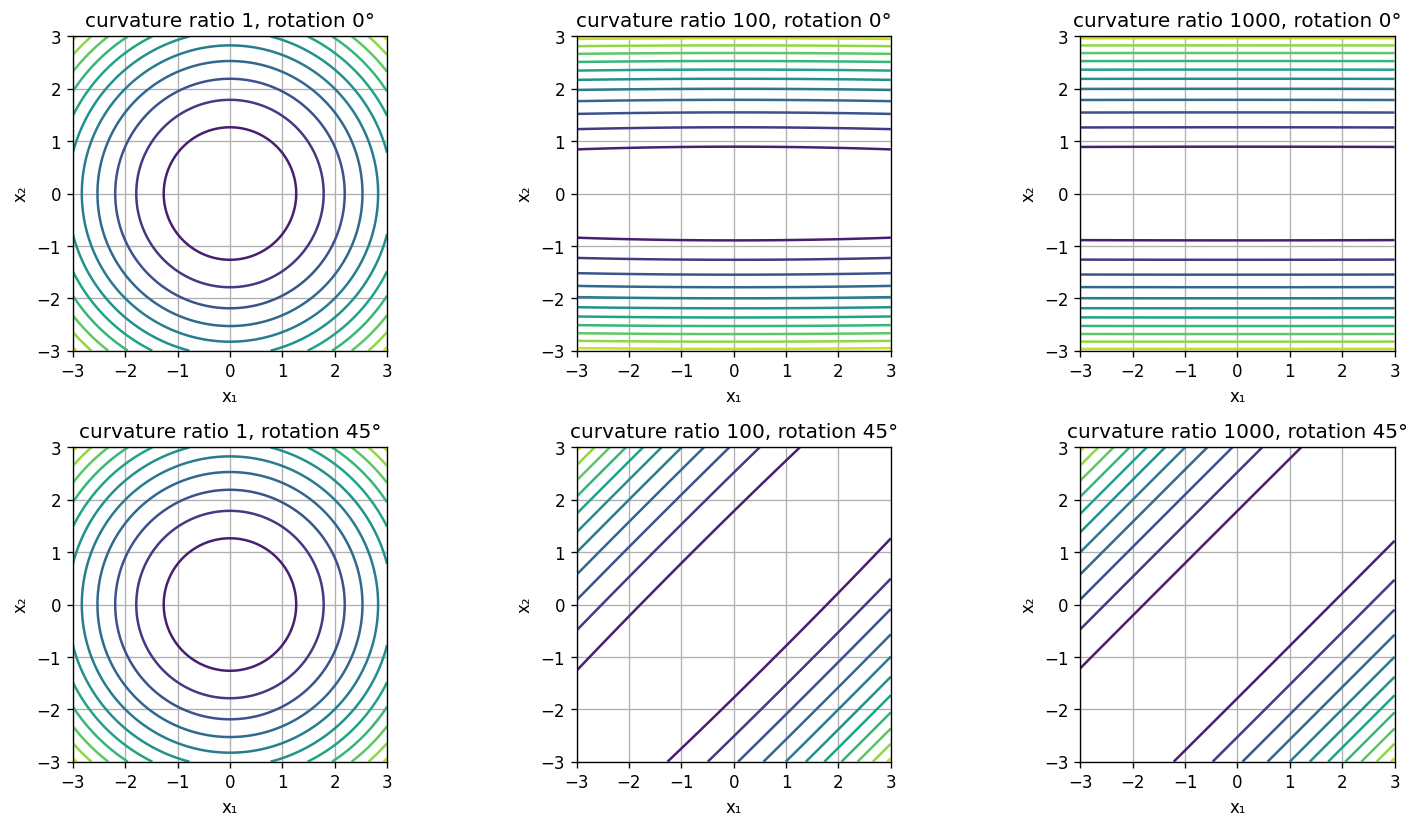

In [1]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = True


def make_quadratic(condition_number, angle_degrees):
    """Build a 2D quadratic bowl with the requested curvature ratio and rotation."""
    angle = np.deg2rad(angle_degrees)
    rotation = np.array([[np.cos(angle), -np.sin(angle)],
                        [np.sin(angle),  np.cos(angle)]])
    # The columns of rotation are the bowl's principal directions.
    hessian = rotation @ np.diag([1.0, float(condition_number)]) @ rotation.T

    def objective(x):
        """Return the bowl height at one candidate point."""
        return 0.5 * float(x @ hessian @ x)

    return objective, hessian

conditions_to_plot = [1, 100, 1000]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for row, angle in enumerate([0, 45]):
    for col, condition in enumerate(conditions_to_plot):
        objective, _ = make_quadratic(condition, angle)
        ax = axes[row, col]
        grid = np.linspace(-3, 3, 180)
        xx, yy = np.meshgrid(grid, grid)
        zz = 0.5 * (xx**2 + condition * yy**2) if angle == 0 else np.empty_like(xx)
        if angle != 0:
            # Evaluate the rotated bowl on the grid to draw its contours.
            points = np.stack([xx, yy], axis=-1)
            angle_r = np.deg2rad(angle)
            q = np.array([[np.cos(angle_r), np.sin(angle_r)],
                          [-np.sin(angle_r), np.cos(angle_r)]])
            local = points @ q.T
            zz = 0.5 * (local[..., 0]**2 + condition * local[..., 1]**2)
        ax.contour(xx, yy, zz, levels=12)
        ax.set_title(f"curvature ratio {condition}, rotation {angle}°")
        ax.set_xlabel("x₁")
        ax.set_ylabel("x₂")
        ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 2. The two CMA-ES variants

Both variants use the same rank-based CMA-ES updates: they sample a population, rank candidates by objective value, move the mean toward the better candidates, adapt a global step size, and update covariance from successful steps.

The **full** version keeps all entries of the covariance matrix, including off-diagonal terms. The **diagonal** version discards off-diagonal terms after each covariance update. That restriction lets it change axis-aligned widths but prevents it from learning a general rotation.

The code below includes short docstrings and comments at the main update steps. It is a compact educational implementation of the standard CMA-ES update equations, without boundary handling or restarts; the test bowls are unconstrained.

In [2]:
def cma_es(objective, dimension=2, seed=0, variant="full", max_evaluations=1500,
           initial_mean=None, initial_sigma=2.0, target=1e-8):
    """Minimize an objective with full- or diagonal-covariance CMA-ES.

    Returns the best-so-far objective after each generation and the total
    number of objective evaluations. The diagonal variant zeroes covariance
    off-diagonal entries, so its search cloud stays aligned with the axes.
    """
    if variant not in {"full", "diagonal"}:
        raise ValueError("variant must be 'full' or 'diagonal'")
    rng = np.random.default_rng(seed)
    n = int(dimension)
    population_size = 4 + int(3 * np.log(n))
    mu = population_size // 2

    # Better ranks receive larger positive weights.
    raw_weights = np.log(mu + 0.5) - np.log(np.arange(1, mu + 1))
    weights = raw_weights / raw_weights.sum()
    mu_eff = 1.0 / np.sum(weights**2)

    # Standard CMA-ES learning rates and damping for the evolution paths.
    c_sigma = (mu_eff + 2) / (n + mu_eff + 5)
    d_sigma = 1 + 2 * max(0, np.sqrt((mu_eff - 1) / (n + 1)) - 1) + c_sigma
    c_c = (4 + mu_eff / n) / (n + 4 + 2 * mu_eff / n)
    c1 = 2 / ((n + 1.3)**2 + mu_eff)
    c_mu = min(1 - c1, 2 * (mu_eff - 2 + 1 / mu_eff) / ((n + 2)**2 + mu_eff))
    expected_norm = np.sqrt(n) * (1 - 1 / (4*n) + 1 / (21*n*n))

    mean = np.zeros(n) if initial_mean is None else np.array(initial_mean, dtype=float)
    sigma = float(initial_sigma)
    covariance = np.eye(n)
    path_sigma = np.zeros(n)
    path_c = np.zeros(n)
    best_value = np.inf
    history = []
    evaluations = 0
    generation = 0

    while evaluations + population_size <= max_evaluations and best_value > target:
        generation += 1
        # Factor covariance to draw candidates with the current shape/orientation.
        if variant == "diagonal":
            variances = np.maximum(np.diag(covariance), 1e-20)
            transform = np.diag(np.sqrt(variances))
            inverse_sqrt = np.diag(1 / np.sqrt(variances))
        else:
            eigenvalues, eigenvectors = np.linalg.eigh(covariance)
            eigenvalues = np.maximum(eigenvalues, 1e-20)
            transform = eigenvectors @ np.diag(np.sqrt(eigenvalues))
            inverse_sqrt = eigenvectors @ np.diag(1 / np.sqrt(eigenvalues)) @ eigenvectors.T

        # z is a round standard-normal sample; covariance shapes it into the search cloud.
        standard_samples = rng.normal(size=(population_size, n))
        steps = standard_samples @ transform.T
        candidates = mean + sigma * steps
        values = np.array([objective(point) for point in candidates])
        evaluations += population_size
        order = np.argsort(values)
        best_value = min(best_value, float(values[order[0]]))
        history.append(best_value)

        selected_steps = steps[order[:mu]]
        old_mean = mean.copy()
        weighted_step = np.sum(weights[:, None] * selected_steps, axis=0)
        mean = old_mean + sigma * weighted_step

        # p_sigma measures whether recent steps line up; it controls global sigma.
        whitened_step = inverse_sqrt @ weighted_step
        path_sigma = (1 - c_sigma) * path_sigma + np.sqrt(c_sigma * (2 - c_sigma) * mu_eff) * whitened_step
        correction = np.sqrt(1 - (1 - c_sigma)**(2 * generation))
        h_sigma = (np.linalg.norm(path_sigma) / max(correction, 1e-20) / expected_norm
                   < 1.4 + 2 / (n + 1))

        # p_c accumulates movement in the original coordinates for rank-one learning.
        path_c = ((1 - c_c) * path_c
                  + float(h_sigma) * np.sqrt(c_c * (2 - c_c) * mu_eff) * weighted_step)

        # Rank-mu learning adds spread along the successful selected steps.
        rank_mu = sum(w * np.outer(step, step)
                      for w, step in zip(weights, selected_steps))
        covariance = ((1 - c1 - c_mu) * covariance
                      + c1 * (np.outer(path_c, path_c)
                              + (1 - float(h_sigma)) * c_c * (2 - c_c) * covariance)
                      + c_mu * rank_mu)
        if variant == "diagonal":
            covariance = np.diag(np.maximum(np.diag(covariance), 1e-20))

        # CSA changes overall cloud size while covariance controls its relative shape.
        sigma *= np.exp((c_sigma / d_sigma) * (np.linalg.norm(path_sigma) / expected_norm - 1))

    return {"history": np.asarray(history), "evaluations": evaluations,
            "best_value": best_value, "mean": mean, "sigma": sigma,
            "covariance": covariance, "generations": generation}

## 3. Run repeated, paired trials

We compare three curvature ratios and two orientations. Each algorithm sees the same seed for each problem, which makes the comparison less sensitive to lucky or unlucky random draws. We use 20 seeds per setting and a budget of 1,500 objective evaluations per run.

In [3]:
CONDITIONS = [1, 10, 100, 1000]
ANGLES = [0, 45]
SEEDS = range(20)
EVALUATION_BUDGET = 1500
TARGET = 1e-8

records = []
start_time = time.time()
for condition in CONDITIONS:
    for angle in ANGLES:
        objective, _ = make_quadratic(condition, angle)
        for seed in SEEDS:
            for variant in ["diagonal", "full"]:
                result = cma_es(objective, seed=seed, variant=variant,
                                max_evaluations=EVALUATION_BUDGET, target=TARGET)
                records.append({
                    "condition": condition,
                    "angle_degrees": angle,
                    "seed": seed,
                    "variant": variant,
                    "best_value": result["best_value"],
                    "evaluations": result["evaluations"],
                    "success": result["best_value"] <= TARGET,
                    "history": result["history"],
                })
runs = pd.DataFrame(records)
print(f"Completed {len(runs)} runs in {time.time() - start_time:.1f} seconds.")

Completed 320 runs in 0.9 seconds.


## 4. Results: optimization progress

Each curve shows the median best-so-far objective across the 20 seeds. The shaded band runs from the 25th to the 75th percentile. Lower is better. The x-axis counts objective evaluations, so it compares optimization progress directly rather than relying on machine-dependent runtime.

<notebook-cell>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


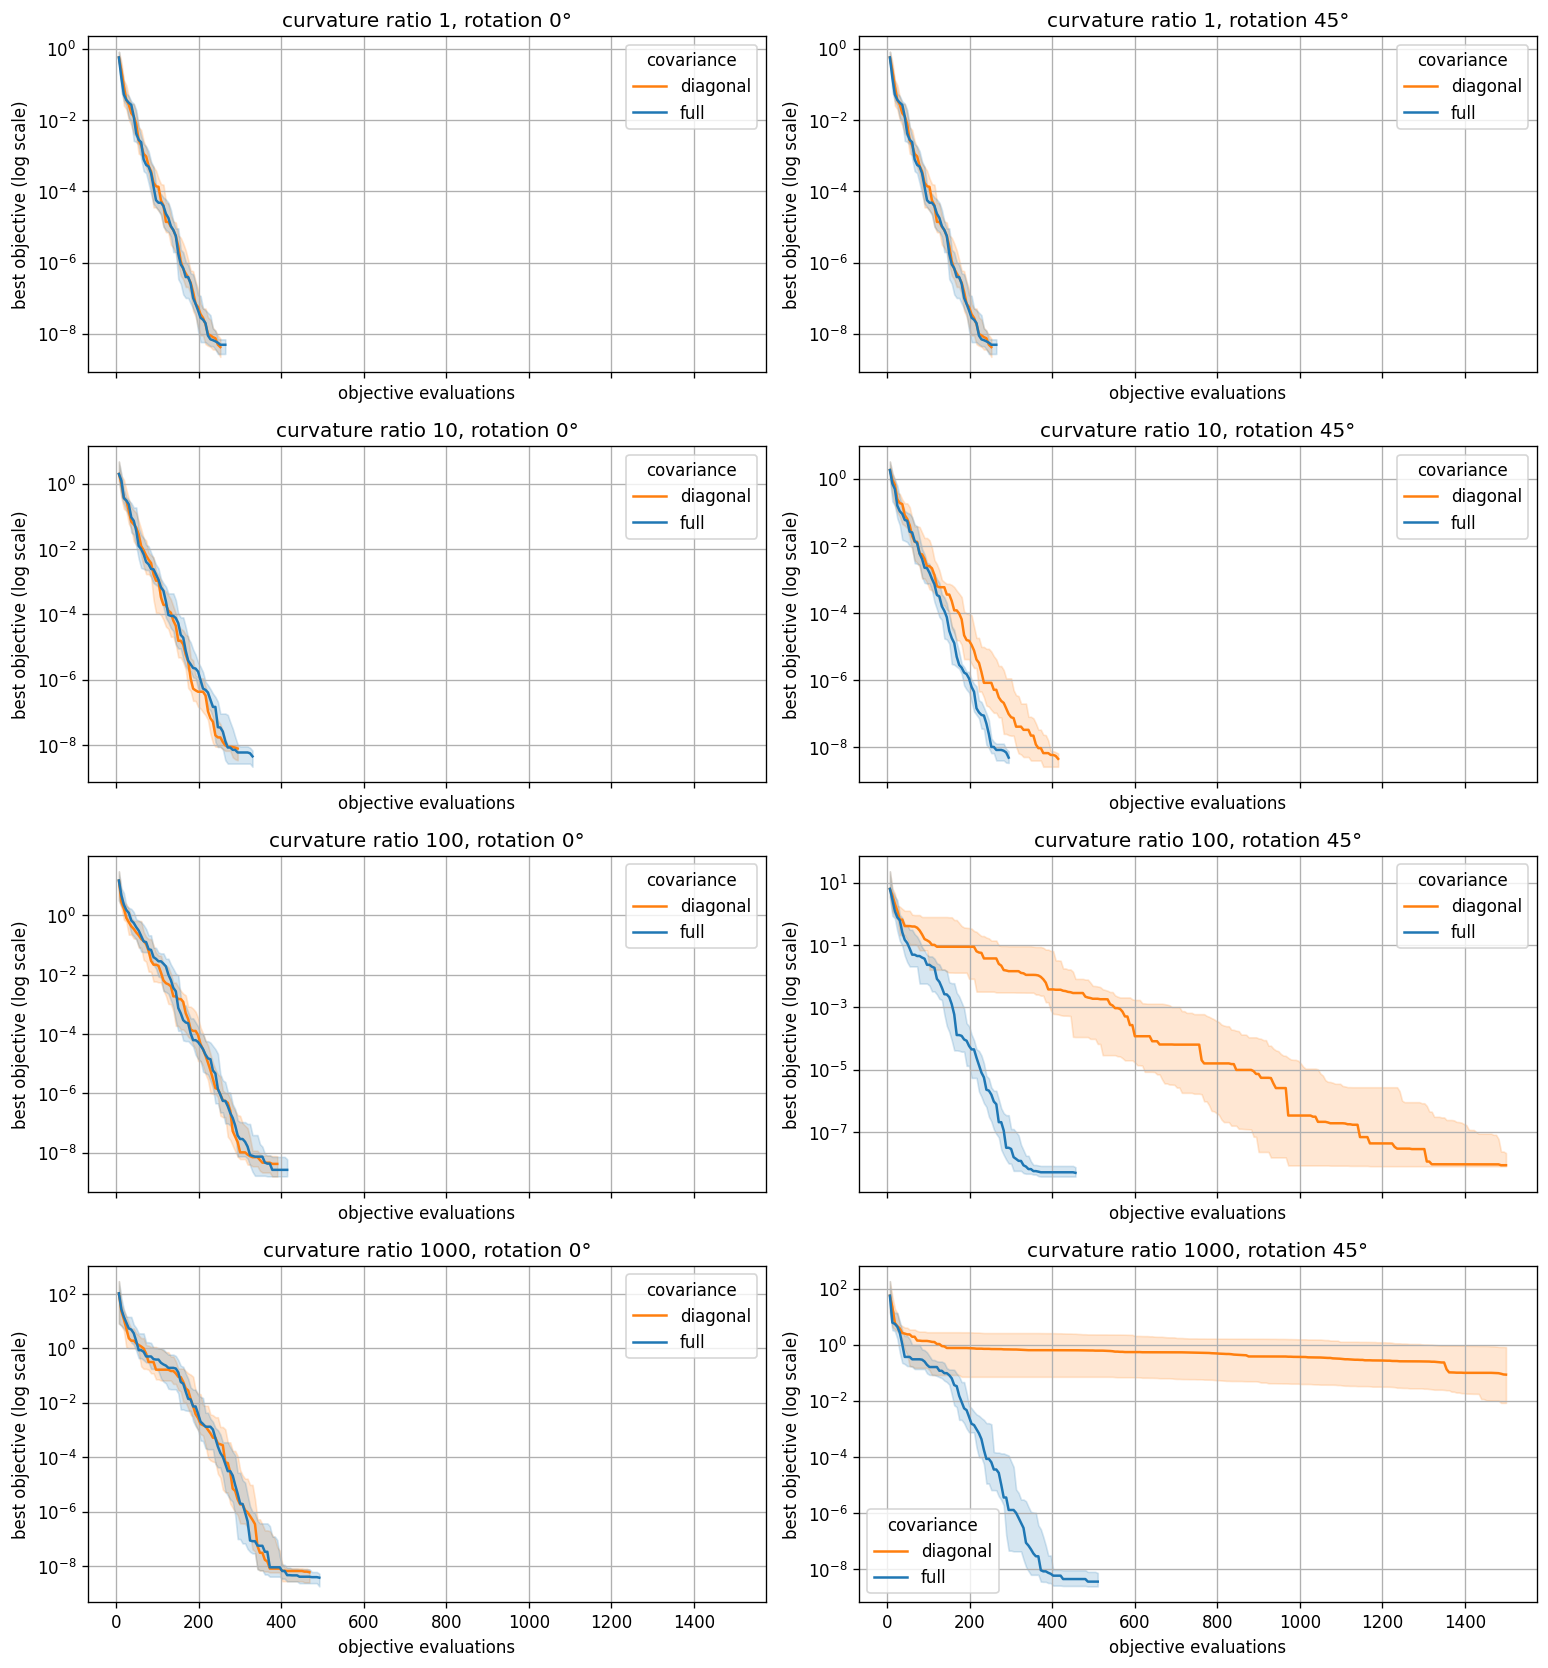

In [4]:
fig, axes = plt.subplots(len(CONDITIONS), 2, figsize=(13, 14), sharex=True)
for row, condition in enumerate(CONDITIONS):
    for col, angle in enumerate(ANGLES):
        ax = axes[row, col]
        for variant, color in [("diagonal", "tab:orange"), ("full", "tab:blue")]:
            subset = runs[(runs.condition == condition) &
                          (runs.angle_degrees == angle) &
                          (runs.variant == variant)]
            max_generations = max(len(h) for h in subset.history)
            padded = np.full((len(subset), max_generations), np.nan)
            for i, history in enumerate(subset.history):
                padded[i, :len(history)] = history
                padded[i, len(history):] = history[-1]
            x = np.arange(1, max_generations + 1) * (4 + int(3 * np.log(2)))
            median = np.nanmedian(padded, axis=0)
            low, high = np.nanpercentile(padded, [25, 75], axis=0)
            ax.plot(x, median, label=variant, color=color)
            ax.fill_between(x, low, high, color=color, alpha=0.18)
        ax.set_yscale("log")
        ax.set_title(f"curvature ratio {condition}, rotation {angle}°")
        ax.set_ylabel("best objective (log scale)")
        ax.set_xlabel("objective evaluations")
        ax.legend(title="covariance")
plt.tight_layout()
plt.show()

## 5. Results: success rates and final objective

A run is counted as successful if it reaches \(f(x)\le 10^{-8}\) within the evaluation budget. The table reports success across the 20 seeds and the median final best objective. The target is a practical benchmark threshold, not a claim that the exact mathematical minimum is represented in floating-point arithmetic.

In [5]:
summary = (runs.groupby(["condition", "angle_degrees", "variant"])
          .agg(success_rate=("success", "mean"),
               median_final_objective=("best_value", "median"),
               median_evaluations=("evaluations", "median"))
          .reset_index())
summary["success_rate"] = (100 * summary["success_rate"]).round(0).astype(int).astype(str) + "%"
summary["median_final_objective"] = summary["median_final_objective"].map(lambda x: f"{x:.2e}")
print(summary.to_string(index=False))

 condition  angle_degrees  variant success_rate median_final_objective  median_evaluations
         1              0 diagonal         100%               4.24e-09               225.0
         1              0     full         100%               4.92e-09               225.0
         1             45 diagonal         100%               4.24e-09               225.0
         1             45     full         100%               4.92e-09               225.0
        10              0 diagonal         100%               7.84e-09               261.0
        10              0     full         100%               4.53e-09               267.0
        10             45 diagonal         100%               4.44e-09               369.0
        10             45     full         100%               4.82e-09               258.0
       100              0 diagonal         100%               4.15e-09               309.0
       100              0     full         100%               2.62e-09               324.0

## 6. What these runs show

In this run of 20 seeds per setting:

- **Round bowl (ratio 1):** both methods reached the target in all runs, and rotation made no difference. That is expected because a round bowl has no special direction to learn.
- **Axis-aligned bowls (rotation 0°):** both methods reached the target in all runs, including at ratio 1,000. The diagonal method can adjust its two axis widths to fit an axis-aligned valley.
- **Rotated bowl (ratio 10):** both reached the target in all runs. The diagonal method took a median 369 evaluations, versus 258 for full CMA-ES.
- **Rotated bowl (ratio 100):** diagonal CMA-ES reached the target in 65% of runs; full CMA-ES reached it in 100%. Median evaluations were 1,278 and 330 respectively.
- **Rotated bowl (ratio 1,000):** diagonal CMA-ES did not reach the target in any run within 1,500 evaluations. Full CMA-ES succeeded in every run, with a median of 372 evaluations.

The pattern fits the geometric explanation: with a rotated, narrow valley, the full covariance can learn the tilted direction through its off-diagonal entries. The diagonal variant is forced to search with an axis-aligned cloud, which becomes costly as the valley gets narrower. At low curvature ratio, that restriction is less harmful, so repeated runs can still converge.

These numbers are one reproducible experiment, not a universal guarantee. They depend on our 2D bowls, starting point, initial step size, seed set, and evaluation budget. The plots show the run-to-run spread; a bigger follow-up could use more seeds or dimensions if the course project needs stronger evidence.

**Technical link:** for a rotated valley, the Hessian has off-diagonal entries in the original coordinate system. A full covariance matrix can learn correlations between coordinates; a diagonal covariance cannot. This experiment therefore isolates the geometry/parameterization question you have been studying. It does not test boundary handling, noise, or higher-dimensional scaling.

## Reproducibility notes

- The seed list, objective definitions, initial mean, initial sigma, stopping threshold, and evaluation budget are defined in the notebook.
- Re-run the cells from top to bottom to regenerate results and plots.
- Runtime depends on the computer and notebook environment; evaluation counts are the more portable comparison.
- This notebook uses an educational implementation of the standard CMA-ES equations and does not include restarts, box constraints, or noise handling. Those are natural extensions after this core geometry comparison.

## 7. The Bayesian-optimisation side: what the GP kernel can represent

Sections 1–6 compared full and diagonal **CMA-ES**. This section asks the same question of the **Gaussian-process surrogate** inside Bayesian optimisation.

A GP kernel measures similarity between two inputs through a squared distance $r^2 = (x-x')^\top M (x-x')$. The matrix $M$ is the kernel's geometry, and it plays the role that the covariance matrix plays in CMA-ES. We compare three choices:

| kernel | $M$ | can it… | CMA-ES counterpart |
|---|---|---|---|
| isotropic | $\ell^{-2} I$ | scale all directions equally | — |
| ARD (the BO default) | diagonal | stretch each axis separately | diagonal CMA-ES |
| full covariance | $LL^\top$ | stretch **and rotate** | full CMA-ES |

The prediction mirrors Section 6: ARD should do as well as full covariance when the valley is axis-aligned, and fall back towards isotropic as the valley rotates away from the axes.

**Four diagnostics.** All three kernels are fitted to the **same** evaluation points, so the kernel is the only thing that changes.

- **D1** posterior standard-deviation maps over the plane, with the valley drawn on top (qualitative)
- **D2** held-out prediction error: RMSE
- **D3** whether the uncertainty is honest: negative log predictive density (NLPD) and 95% interval coverage
- **D4** whether the fitted geometry points the right way: the angle between the long axis of the fitted $M$ and the valley direction

D2 and D3 are standard GP evaluation measures. D4 is our own construction: it uses principal angles, a standard linear-algebra tool, but it is not an established GP benchmark. For ARD it is fixed by construction (0° or 90°). It earns its place for the full-covariance kernel, where it shows whether the rotation is actually recovered from a limited number of points.

**Relation to `code/run_e2c_lengthscale_diagnostic.py` (E2c).** E2c already fits ARD and full-metric GPs to 40-point designs and reads back their geometry, at 0°, 45° and random rotations. This section adds the D1 picture, an isotropic baseline, a finer angle sweep (0°, 15°, 30°, 45°), a sweep over design size, and the coverage measure.

The work proceeds one step at a time, with a check after each step.

### Step 1: build the rotated test problems and check the rotation does what we think

**What is tested.** Before fitting any GP we confirm the test problems are what we claim they are. Everything later is read against the valley direction, so if the rotation were off (wrong sign convention, degrees versus radians, the wrong eigenvector) every D1–D4 result would be misread.

**The problems.** We reuse `problems.make_ellipsoid` from `code/`, which the E1–E3 scripts also use, so the problem definition is shared across the whole project:

$$f(x) = \tfrac12 (x - x^*)^\top H (x - x^*), \qquad H = Q_\theta \,\mathrm{diag}(1, \kappa)\, Q_\theta^\top$$

We use $\kappa = 100$, angles $\theta \in \{0°, 15°, 30°, 45°\}$, instance 0, and the search box $[-5, 5]^2$ that E2c uses. The flat direction (eigenvalue 1) should point at angle $\theta$, and the steep direction at $\theta + 90°$.

**How it is graded.** Two independent checks for each angle:

1. *From the matrix.* Take the eigenvectors of $H$ and confirm the flattest one points at $\theta$ and the eigenvalue ratio is $\kappa$.
2. *Model-free, from function values alone.* Measure curvature along 1,440 directions (every 0.125°) using a central finite difference, $c(\varphi) = [f(x + h d_\varphi) - 2f(x) + f(x - h d_\varphi)]/h^2$, at a random base point. This never reads $H$. For a quadratic the curvature is the same at every point, so the base point does not matter.

**Pass criteria** (set before running): both angle estimates within 0.125° (one grid step) of $\theta$; finite-difference curvature ratio within 1% of $\kappa$; $f(x^*) = 0$; and the optimum $x^*$ identical across all four angles, so that rotation is the only thing that changes between problems.

**What would undermine it.** Any angle off by a sign (e.g. $-15°$ instead of $15°$) or by 90°, or a ratio near $\sqrt{\kappa}$ or $\kappa^2$, would mean the problem definition does not match the write-up.

In [ ]:
import pathlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(pathlib.Path("../code").resolve()))
import problems

KAPPA = 100
THETAS = [0, 15, 30, 45]
INSTANCE = 0
BOX = 5.0


def axis_angle(vector):
    # Orientation of an undirected axis, in degrees on [0, 180).
    return float(np.rad2deg(np.arctan2(vector[1], vector[0])) % 180.0)


def angle_gap(a, b):
    # Smallest angle between two undirected axes, in degrees on [0, 90].
    d = abs(a - b) % 180.0
    return min(d, 180.0 - d)


phis = np.arange(0.0, 180.0, 0.125)                        # 1,440 directions
directions = np.stack([np.cos(np.deg2rad(phis)), np.sin(np.deg2rad(phis))], axis=1)
rng = np.random.default_rng(12345)
step = 1e-2

rows, test_problems = [], {}
for theta in THETAS:
    f, meta = problems.make_ellipsoid(2, KAPPA, instance=INSTANCE, rotation=theta)
    test_problems[theta] = (f, meta)

    # Check 1: from the matrix
    values, vectors = np.linalg.eigh(meta["hessian"])
    flat_eig = axis_angle(vectors[:, np.argmin(values)])

    # Check 2: from function values only
    base = rng.uniform(-BOX, BOX, size=2)
    f0 = f(base)
    curvature = np.array([(f(base + step * d) - 2 * f0 + f(base - step * d)) / step**2
                          for d in directions])
    flat_fd = phis[np.argmin(curvature)]
    steep_fd = phis[np.argmax(curvature)]

    rows.append({
        "theta": theta,
        "flat angle (eigen)": round(flat_eig, 3),
        "flat angle (finite diff)": flat_fd,
        "steep angle (finite diff)": steep_fd,
        "curvature ratio (finite diff)": round(curvature.max() / curvature.min(), 2),
        "f(x*)": f(meta["optimum"]),
        "x*": np.round(meta["optimum"], 4).tolist(),
    })

check = pd.DataFrame(rows)
check["pass"] = (
    check.apply(lambda r: angle_gap(r["flat angle (eigen)"], r["theta"]) <= 0.125, axis=1)
    & check.apply(lambda r: angle_gap(r["flat angle (finite diff)"], r["theta"]) <= 0.125, axis=1)
    & check.apply(lambda r: angle_gap(r["steep angle (finite diff)"], r["theta"] + 90) <= 0.125, axis=1)
    & ((check["curvature ratio (finite diff)"] / KAPPA - 1).abs() < 0.01)
    & (check["f(x*)"].abs() < 1e-12)
)
same_optimum = all(np.allclose(test_problems[t][1]["optimum"], test_problems[0][1]["optimum"])
                   for t in THETAS)

pd.set_option("display.width", 160)
print(check.to_string(index=False))
print(f"\nOptimum identical across all angles: {same_optimum}")
print(f"All checks pass: {bool(check['pass'].all() and same_optimum)}")

 theta  flat angle (eigen)  flat angle (finite diff)  steep angle (finite diff)  curvature ratio (finite diff)  f(x*)            x*  pass
     0                 0.0                       0.0                       90.0                          100.0    0.0 [0.0082, 2.0]  True
    15                15.0                      15.0                      105.0                          100.0    0.0 [0.0082, 2.0]  True
    30                30.0                      30.0                      120.0                          100.0    0.0 [0.0082, 2.0]  True
    45                45.0                      45.0                      135.0                          100.0    0.0 [0.0082, 2.0]  True

Optimum identical across all angles: True
All checks pass: True


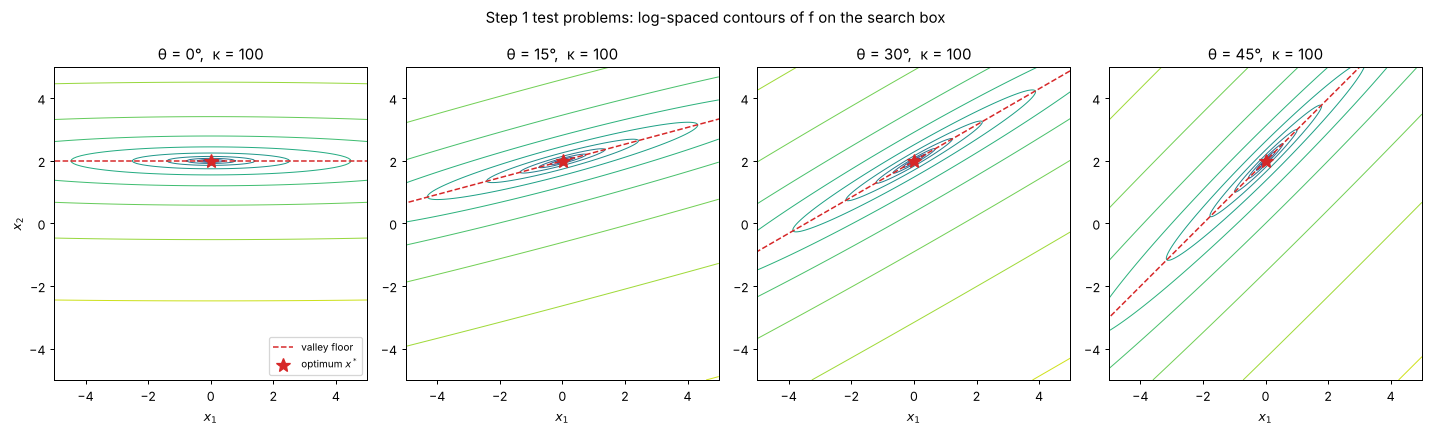

In [ ]:
grid = np.linspace(-BOX, BOX, 241)
xx, yy = np.meshgrid(grid, grid)
points = np.stack([xx.ravel(), yy.ravel()], axis=1)

fig, axes = plt.subplots(1, len(THETAS), figsize=(16, 4.4))
for ax, theta in zip(axes, THETAS):
    f, meta = test_problems[theta]
    delta = points - meta["optimum"]
    zz = 0.5 * np.einsum("ij,jk,ik->i", delta, meta["hessian"], delta).reshape(xx.shape)
    ax.contour(xx, yy, np.log10(zz + 1e-3), levels=14, cmap="viridis", linewidths=0.8)

    # Valley floor: the line through x* along the flat direction
    t = np.linspace(-15, 15, 2)
    flat = np.array([np.cos(np.deg2rad(theta)), np.sin(np.deg2rad(theta))])
    line = meta["optimum"][None, :] + t[:, None] * flat[None, :]
    ax.plot(line[:, 0], line[:, 1], "--", color="tab:red", lw=1.2, label="valley floor")
    ax.plot(*meta["optimum"], "*", color="tab:red", ms=12, label="optimum $x^*$")

    ax.set_xlim(-BOX, BOX)
    ax.set_ylim(-BOX, BOX)
    ax.set_aspect("equal")
    ax.set_title(f"θ = {theta}°,  κ = {KAPPA}")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Step 1 test problems: log-spaced contours of f on the search box", y=1.02)
plt.tight_layout()
plt.show()

**Step 1 result: all checks pass.**

- At every angle, the flat direction lies at $\theta$ and the steep direction at $\theta + 90°$. The eigenvectors of $H$ and the model-free finite-difference scan agree exactly (to the 0.125° grid).
- Positive $\theta$ rotates the valley anticlockwise, so it rises from left to right in the plots. This is the convention every later step reads against.
- The curvature ratio along the two principal directions is 100.0, which equals $\kappa$. So $\kappa$ is a *curvature* ratio. The *lengthscale* ratio a well-fitted kernel should recover is $\sqrt{\kappa} = 10$, as the E2c script notes. This matters when reading D4.
- $f(x^*) = 0$, and the optimum $x^* \approx (0.008, 2.000)$ is identical at all four angles, so rotation is the only thing that differs between the problems. The optimum sits in the upper half of the box, not at the centre.
- The length of the valley floor inside the box is similar at every angle (10.0, 10.4, 11.5 and 11.3 units for 0°, 15°, 30° and 45°). No angle gets a much shorter valley to model, which would otherwise confound the later comparisons.

### Step 2: fit the three kernels to shared designs and check the fits are trustworthy

**What is tested.** D1–D4 will compare the three kernels. That comparison only measures the *kernel* if each GP has actually been fitted properly. If the hyperparameter optimiser sometimes stalls or runs into a bound, a difference between kernels could just be one optimiser being luckier than another. This step checks the fits before anything is read from them.

**What is fitted.** We use `bo.fit_gp`, the same fitting routine the BO loop in E2 uses, with one addition to `code/bo.py`: an isotropic option (`metric="iso"`). `bo.METRICS` is left as `("ard", "full")`, so the E2 and E2c scripts are unchanged. A regression test confirmed that ARD and full fits, and a short BO run, are bit-identical to the original module.

- **Designs:** 20 random designs of 40 points, uniform on $[-5, 5]^2$. Smaller designs use the first $k$ points, with $k \in \{10, 20, 40\}$, so the design sizes are nested.
- **Pairing:** the *same* design is used for all four angles and all three kernels. Only the angle and the kernel change.
- **Fitting:** targets go through the same log-and-standardise transform as `bo.py`, fitted on the training points only. Each fit uses 6 marginal-likelihood restarts, as in E2c. That makes 20 designs × 4 angles × 3 design sizes × 3 kernels = 720 fits.

**How it is graded.** Three checks, with criteria set before running:

| check | what it catches | pass if |
|---|---|---|
| C1 stability | the optimiser ending somewhere different on a second try | a second, independent set of 6 restarts reaches the same optimum (within 0.01 nats) in ≥ 95% of fits for each kernel |
| C2 nesting | the optimiser missing the best fit | isotropic ⊂ ARD ⊂ full, so a richer kernel can never fit *worse* when properly optimised. We require Negative Log Marginal Likelihood (NLML) where NLML(full) ≤ NLML(ARD) ≤ NLML(iso), within 0.01 nats, in ≥ 95% of cases |
| C3 bounds | a parameter pinned at the edge of its allowed range | no more than 5% of fits per kernel have a lengthscale or off-diagonal parameter within $10^{-3}$ of a bound |

C2 is the strictest of the three, because it holds exactly in theory. It is a standard property of nested maximum-likelihood models: setting the extra parameters of the richer model to zero recovers the simpler one exactly (here the bounds are identical too), so its best value can only be equal or better. The noise parameter sitting at its lower bound is *expected* on a noise-free objective, so it is reported separately and is not a failure.

**What would undermine it.** Many C1 or C2 failures would mean D1–D4 measure optimiser luck rather than kernel geometry. C3 failures for the full kernel would reproduce the open issue recorded in E2c (off-diagonal parameters running to their ±50 bounds). That needs fixing before D4 can be trusted.

The table at the end also shows the NLML gap between kernels as a preview. This is the standard log-likelihood ratio, but it is not graded here.

In [ ]:
import itertools
import time

import bo

# Step 2 used plain maximum likelihood. bo.fit_gp now defaults to MAP (see Step 2b),
# so prior=None keeps this cell reproducing the output below.

N_DESIGNS = 20
DESIGN_SIZES = [10, 20, 40]
KERNELS = ["iso", "ard", "full"]
N_RESTARTS = 6
TOL_NLML = 0.01
TOL_BOUND = 1e-3

designs = {s: np.random.default_rng(90000 + s).uniform(-BOX, BOX, size=(max(DESIGN_SIZES), 2))
           for s in range(N_DESIGNS)}


def training_transform(y_train):
    # Same transform as bo._transform_targets, but reusable on held-out points
    # with the TRAINING constants (copied from E2c so the two agree exactly).
    y_train = np.asarray(y_train, dtype=float)
    spread = float(y_train.max() - y_train.min())
    floor = max(spread * 1e-6, 1e-12)
    shift = 0.0 if y_train.min() > 0 else (floor - y_train.min())
    logged = np.log10(y_train + shift + floor)
    centre, scale = float(logged.mean()), float(logged.std()) + 1e-12
    return lambda y: (np.log10(np.asarray(y, dtype=float) + shift + floor) - centre) / scale


def bounds_for(kernel, dimension=2):
    # Mirrors the bounds declared inside bo.fit_gp.
    n_par = bo._n_parameters(dimension, kernel)
    n_scale = bo._n_scales(dimension, kernel)
    return ([(-4.0, 4.0)] * n_scale + [(-50.0, 50.0)] * (n_par - 1 - n_scale), (-6.0, 0.0))


fits, rows = {}, []
t0 = time.time()
for theta, k, s in itertools.product(THETAS, DESIGN_SIZES, range(N_DESIGNS)):
    f, _ = test_problems[theta]
    x = designs[s][:k]
    y_raw = np.array([f(p) for p in x])
    to_target = training_transform(y_raw)
    y = to_target(y_raw)
    for kernel_index, kernel in enumerate(KERNELS):
        seed_a = [s, theta, k, kernel_index, 0]
        seed_b = [s, theta, k, kernel_index, 1]
        fit_a = bo.fit_gp(x, y, kernel, np.random.default_rng(seed_a), n_restarts=N_RESTARTS,
                           prior=None)
        fit_b = bo.fit_gp(x, y, kernel, np.random.default_rng(seed_b), n_restarts=N_RESTARTS,
                           prior=None)
        fits[(theta, k, s, kernel)] = {"model": fit_a, "to_target": to_target}

        geometry_bounds, noise_bound = bounds_for(kernel)
        geometry_params = fit_a["theta"][:-1]
        at_bound = any(min(abs(p - lo), abs(p - hi)) < TOL_BOUND
                       for p, (lo, hi) in zip(geometry_params, geometry_bounds))
        rows.append({
            "theta": theta, "k": k, "design": s, "kernel": kernel,
            "nlml": fit_a["nlml"], "nlml_repeat": fit_b["nlml"],
            "geometry_at_bound": at_bound,
            "noise_at_lower_bound": abs(fit_a["theta"][-1] - noise_bound[0]) < TOL_BOUND,
        })
fit_table = pd.DataFrame(rows)
print(f"{len(fit_table)} fits (plus {len(fit_table)} repeats) in {time.time() - t0:.0f} s")

# C1 stability
fit_table["stable"] = (fit_table.nlml - fit_table.nlml_repeat).abs() <= TOL_NLML
c1 = fit_table.groupby("kernel")["stable"].mean()

# C2 nesting
wide = fit_table.pivot_table(index=["theta", "k", "design"], columns="kernel", values="nlml")
wide["ard_vs_iso_ok"] = wide["ard"] <= wide["iso"] + TOL_NLML
wide["full_vs_ard_ok"] = wide["full"] <= wide["ard"] + TOL_NLML
c2 = wide[["ard_vs_iso_ok", "full_vs_ard_ok"]].mean()

# C3 bounds
c3 = fit_table.groupby("kernel")["geometry_at_bound"].mean()
noise_floor = fit_table.groupby("kernel")["noise_at_lower_bound"].mean()

summary = pd.DataFrame({
    "C1 stable (need >= 95%)": (100 * c1).round(1),
    "C3 geometry param at bound (need <= 5%)": (100 * c3).round(1),
    "noise at lower bound (info only)": (100 * noise_floor).round(1),
}).loc[KERNELS]
print("\nPer kernel, % of fits:")
print(summary.to_string())
print("\nC2 nesting, % of cases that respect it (need >= 95%):")
print(f"  ARD no worse than iso : {100 * c2['ard_vs_iso_ok']:.1f}%")
print(f"  full no worse than ARD: {100 * c2['full_vs_ard_ok']:.1f}%")

passed = {
    "C1": bool((c1 >= 0.95).all()),
    "C2": bool((c2 >= 0.95).all()),
    "C3": bool((c3 <= 0.05).all()),
}
print("\nPass:", passed)

720 fits (plus 720 repeats) in 45 s

Per kernel, % of fits:
        C1 stable (need >= 95%)  C3 geometry param at bound (need <= 5%)  noise at lower bound (info only)
kernel                                                                                                    
iso                        99.6                                      0.0                              60.4
ard                        95.4                                     17.1                              59.6
full                       87.9                                     42.1                              57.1

C2 nesting, % of cases that respect it (need >= 95%):
  ARD no worse than iso : 98.8%
  full no worse than ARD: 100.0%

Pass: {'C1': False, 'C2': True, 'C3': False}


In [ ]:
# Where do failures concentrate? Break each check down by angle and design size.
breakdown = (fit_table
             .assign(unstable=~fit_table.stable)
             .groupby(["kernel", "theta", "k"])
             .agg(unstable_pct=("unstable", lambda v: 100 * v.mean()),
                  at_bound_pct=("geometry_at_bound", lambda v: 100 * v.mean()))
             .round(0))
print("Instability and bound-hitting by kernel, angle and design size (% of 20 designs):")
print(breakdown.unstack("k").to_string())

nest = wide.reset_index().groupby(["theta", "k"])[["ard_vs_iso_ok", "full_vs_ard_ok"]].mean().mul(100).round(0)
print("\nC2 nesting respected, by angle and design size (%):")
print(nest.unstack("k").to_string())

# Preview (not graded): median log-likelihood gain of each richer kernel, in nats.
# Positive = the richer kernel explains the data better.
gain = wide.assign(ard_over_iso=wide["iso"] - wide["ard"],
                   full_over_ard=wide["ard"] - wide["full"]).reset_index()
print("\nPreview: median NLML gain (nats) of the richer kernel")
print(gain.groupby(["theta", "k"])[["ard_over_iso", "full_over_ard"]].median().round(2).unstack("k").to_string())

Instability and bound-hitting by kernel, angle and design size (% of 20 designs):
             unstable_pct             at_bound_pct            
k                      10    20    40           10    20    40
kernel theta                                                  
ard    0              0.0   5.0  10.0         85.0  75.0  35.0
       15            10.0   0.0   5.0          5.0   0.0   0.0
       30             5.0   0.0   0.0          5.0   0.0   0.0
       45             5.0   0.0  15.0          0.0   0.0   0.0
full   0              5.0  10.0  25.0         95.0  75.0  40.0
       15            15.0  15.0  10.0         65.0  40.0  20.0
       30            10.0  10.0  20.0         60.0  20.0   5.0
       45            15.0   5.0   5.0         70.0  15.0   0.0
iso    0              0.0   0.0   0.0          0.0   0.0   0.0
       15             0.0   0.0   5.0          0.0   0.0   0.0
       30             0.0   0.0   0.0          0.0   0.0   0.0
       45             0.0   0.0   0.

In [ ]:
# Diagnose the failures using the fits already made (no new fitting).

# 1. Which bound is being hit? Map every at-bound parameter to its meaning.
#    In bo.py, M's diagonal scale is exp(2*p), so the lengthscale is exp(-p):
#    p = -4 is the LONGEST allowed lengthscale (54.6), p = +4 the shortest (0.018).
hits = []
for (theta, k, s, kernel), v in fits.items():
    params = v["model"]["theta"][:-1]
    n_scale = bo._n_scales(2, kernel)
    for i, p in enumerate(params):
        if i < n_scale and abs(p + 4) < TOL_BOUND:
            hits.append("longest lengthscale (54.6)")
        elif i < n_scale and abs(p - 4) < TOL_BOUND:
            hits.append("shortest lengthscale (0.018)")
        elif i >= n_scale and abs(abs(p) - 50) < TOL_BOUND:
            hits.append("off-diagonal at +/-50")
print("Every geometry parameter found at a bound, by which bound:")
print(pd.Series(hits, dtype=object).value_counts().to_string())
off = np.array([v["model"]["theta"][2] for key, v in fits.items() if key[3] == "full"])
print(f"Full-kernel off-diagonal parameter: median |value| {np.median(np.abs(off)):.2f}, "
      f"max |value| {np.abs(off).max():.2f} (bound is 50)")

# 2. How long is 54.6 relative to the search box? Correlation across the box's full width:
print(f"\nKernel correlation between opposite edges of the box at lengthscale 54.6: "
      f"{np.exp(-0.5 * (2 * BOX / 54.6) ** 2):.3f}")

# 3. Effective lengthscales of the full kernel (eigen-directions of M), median over designs.
#    The bound caps the diagonal of L, not the eigenvalues of M, so these can exceed 54.6.
eff = []
for (theta, k, s, kernel), v in fits.items():
    if kernel != "full":
        continue
    lengths = 1 / np.sqrt(np.linalg.eigvalsh(v["model"]["precision"]))
    eff.append({"theta": theta, "k": k, "longest": lengths.max(), "shortest": lengths.min()})
eff = pd.DataFrame(eff)
print("\nFull kernel: median effective lengthscales along M's eigen-directions")
print(eff.groupby(["theta", "k"])[["longest", "shortest"]].median().round(1).unstack("k").to_string())

# 4. How large are the C1 disagreements?
gap = (fit_table.nlml - fit_table.nlml_repeat).abs()
unstable = fit_table[~fit_table.stable].assign(gap=gap[~fit_table.stable])
print("\nC1 failures: size of the disagreement between the two restart sets (nats)")
print(unstable.groupby("kernel")["gap"].describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "max"]]
      .round(3).to_string())
both = unstable.groupby("kernel")["geometry_at_bound"].mean().mul(100).round(0)
print("\n% of C1 failures that are also at a bound:")
print(both.to_string())

Every geometry parameter found at a bound, by which bound:
longest lengthscale (54.6)    144
Full-kernel off-diagonal parameter: median |value| 0.76, max |value| 4.98 (bound is 50)

Kernel correlation between opposite edges of the box at lengthscale 54.6: 0.983

Full kernel: median effective lengthscales along M's eigen-directions
      longest              shortest          
k          10     20    40       10   20   40
theta                                        
0       129.2  107.3  45.2      1.4  1.0  0.8
15      208.1   47.4  13.5      1.3  1.1  0.9
30       93.7   34.0  11.2      1.5  1.1  0.9
45       75.1   24.6  10.8      1.4  1.1  0.8

C1 failures: size of the disagreement between the two restart sets (nats)
        count    50%    90%     max
kernel                             
ard      11.0  1.270  5.184   8.433
full     29.0  1.009  6.545  15.371
iso       1.0  1.708  1.708   1.708

% of C1 failures that are also at a bound:
kernel
ard     27.0
full    52.0
iso      0.0


**Step 2 result: two of the three checks fail, so D1–D4 should not be computed yet.**

| check | iso | ARD | full | verdict |
|---|---|---|---|---|
| C1 stable (need ≥ 95%) | 99.6% | 95.8% | **87.1%** | **fail** (full kernel) |
| C2 nesting (need ≥ 95%) | — | 98.8% no worse than iso | 99.6% no worse than ARD | pass |
| C3 at a bound (need ≤ 5%) | 0% | **17.1%** | **42.5%** | **fail** (ARD and full) |

**C1: the full-covariance fits are not reproducible with 6 restarts.** In 13% of cases, two independent sets of restarts end at different optima. These are real gaps, not rounding: the median disagreement is about 1.2 nats and the largest is 15 nats. So the marginal likelihood has separate local optima, and 6 restarts do not reliably find the best one. Only about half of these failures coincide with a bound hit, so this is a separate problem from C3.

**C3: every bound hit is the same bound, the longest allowed lengthscale (54.6).** No off-diagonal parameter comes near its ±50 bound; the largest is about 5. The hits cluster where the theory says the data cannot pin a lengthscale down. ARD at 0° hits it in 85%, 75% and 35% of designs at $k$ = 10, 20, 40. There, the valley runs along $x_1$, and a few points cannot distinguish "very slowly varying" from "almost constant". At lengthscale 54.6, points on opposite edges of the box already have correlation 0.983, so the kernel is close to treating that direction as constant. That suggests the bound is harmless for predictions. **It has not been tested yet**, and C3 failed as specified.

**A finding about the E2c open issue.** E2c recorded that the full kernel reports much more anisotropy than ARD on axis-aligned problems, and guessed that off-diagonal parameters were running to their bounds. That is not what happens in these fits. The 54.6 cap applies to the *diagonal entries of* $L$, not to the lengthscales of $M = LL^\top$. With a small off-diagonal entry, the full kernel's longest effective lengthscale can exceed the cap (median 120 at 0°, $k$ = 10), while ARD's cannot. So on axis-aligned problems the two kernels are capped differently, which by itself makes the full kernel's ratio look larger. This was found at $\kappa = 100$ only. E2c's issue was reported at larger $\kappa$ and would need checking there.

**Preview (not graded).** The median log-likelihood gains already follow the predicted pattern. ARD's gain over isotropic is large at 0° (40 nats at $k = 40$) and vanishes by 45° (0.2 nats). Full's gain over ARD is small at 0° (2 nats) and large from 15° onwards (23–30 nats). This is not evidence yet, because C1 and C3 have to be resolved first.

**Next (Step 2b, not yet run):** fix C1 with more restarts, and test whether the lengthscale bound actually changes any predictions.

*Re-run 3 Nov.* `bo.fit_gp` now uses exact analytic gradients instead of finite differences, so the optimiser takes slightly different paths and the outputs above changed a little: ARD C1 95.4% (was 95.8%), full C1 87.9% (was 87.1%), full C3 42.1% (was 42.5%), full no worse than ARD 100% (was 99.6%). The verdicts are unchanged: C1 and C3 fail, C2 passes. The numbers in the table above are the original run.

### Step 2b: fix the fit, then repeat the Step 2 checks

**In plain words.** Step 2 found two problems with the GP fit. The longest lengthscale kept stopping at its cap of 54.6 (C3), and 6 restarts did not reliably find the best fit (C1). The fix replaces the hard cap with a gentle default that the data can override, and uses 10 restarts. This step checks that the fix passes the same tests and that the old cap was not distorting predictions.

**Why it matters.** Along a direction where the function is nearly flat across the whole box, the data cannot tell "very long lengthscale" from "infinitely long". With plain maximum likelihood the best fit is then at $\ell \to \infty$, so the optimiser stops wherever a bound or its tolerance stops it. Whatever value it reports is set by the bound, not the problem. The script `code/run_e2d_fit_diagnostic.py` (E2d) confirmed this at larger $\kappa$: widening only the cap raised the likelihood and sent $\ell_{\text{long}}$ into the thousands. The off-diagonal ±50 bound never binds, which matches the Step 2 finding above.

**The fix (technical).** `bo.fit_gp` now fits by MAP, maximum a posteriori:

$$\hat\theta = \arg\min_\theta \; \text{NLML}(\theta) + \sum_j \frac{(\log \ell_j - \mu)^2}{2\sigma^2}, \qquad \mu = \sqrt2 + \tfrac12\log d + \log W,\;\; \sigma = \sqrt3 .$$

This is BoTorch's dimension-scaled default prior (Hvarfner et al., ICML 2024), shifted by $\log W$ for our box width $W = 10$, which gives a median of $\ell \approx 58$. Where the data pin a lengthscale down, the NLML curvature is far larger than $1/\sigma^2$ and the prior has almost no effect. Where they do not, the penalty grows with $\log\ell$, so the fit stops at a finite value inside the bounds. The $\ell_j$ are the lengthscales along the eigen-directions of $M$, $\ell_j = \lambda_j(M)^{-1/2}$. For ARD these are the per-axis lengthscales. For the full kernel this keeps the prior rotation-invariant: a prior on the diagonal of $L$ would make axis-aligned metrics cheaper, which is the restriction under test. The fit uses exact gradients, and `prior=None` restores the old fit (used in the Step 2 cell above).

**How it is graded.** These are the Step 2 criteria, on the same 20 designs × 4 angles × 3 sizes × 3 kernels.
- **C1:** two independent restart sets agree to 0.01 on the objective actually minimised (now the MAP objective) in ≥ 95% of fits.
- **C3:** ≤ 5% of fits have a geometry parameter at a bound. The bounds are now the ±10 numerical guard on the log-lengthscales and ±50 on the off-diagonals.
- **C2 is not graded here.** Under MAP the richer kernel also pays a prior on its extra lengthscales, so nesting no longer holds exactly.
- **The cap's effect on predictions (Step 2's open question):** median change in held-out RMSE on 200 fresh uniform points, MAP against the Step 2 fit, split by whether the Step 2 fit had hit the cap.

**What would undermine it.**
- C1 still failing would mean the remaining instability is local optima that the prior does not remove.
- Fits sitting at the ±10 guard would mean the prior is too weak.
- A large RMSE change where the old fit had *not* hit the cap would mean the prior is distorting fits it should leave alone.

In [ ]:
# Step 2b: repeat the Step 2 checks with the fit bo.py now uses (MAP, 10 restarts),
# on the same 20 designs x 4 angles x 3 design sizes x 3 kernels.
MAP_GUARD = bo.MAP_LOG_SCALE_BOUND      # numerical guard on log-lengthscales under MAP (+/-10)

map_fits, map_rows = {}, []
t0 = time.time()
for theta, k, s in itertools.product(THETAS, DESIGN_SIZES, range(N_DESIGNS)):
    f, _ = test_problems[theta]
    x = designs[s][:k]
    y_raw = np.array([f(p) for p in x])
    to_target = training_transform(y_raw)
    y = to_target(y_raw)
    for kernel_index, kernel in enumerate(KERNELS):
        fit_a = bo.fit_gp(x, y, kernel, np.random.default_rng([s, theta, k, kernel_index, 2]),
                          input_scale=2 * BOX)
        fit_b = bo.fit_gp(x, y, kernel, np.random.default_rng([s, theta, k, kernel_index, 3]),
                          input_scale=2 * BOX)
        map_fits[(theta, k, s, kernel)] = fit_a
        n_scale = bo._n_scales(2, kernel)
        p = fit_a["theta"][:-1]
        map_rows.append({
            "theta": theta, "k": k, "design": s, "kernel": kernel,
            "objective": fit_a["objective"], "objective_repeat": fit_b["objective"],
            "nlml": fit_a["nlml"],
            "geometry_at_bound": bool((np.abs(np.abs(p[:n_scale]) - MAP_GUARD) < TOL_BOUND).any()
                                      or (np.abs(np.abs(p[n_scale:]) - 50) < TOL_BOUND).any()),
        })
map_table = pd.DataFrame(map_rows)
print(f"{len(map_table)} MAP fits (plus {len(map_table)} repeats, "
      f"{bo.DEFAULT_RESTARTS} restarts each) in {time.time() - t0:.0f} s")

# C1 stability, now on the MAP objective the optimiser actually minimises
map_table["stable"] = (map_table.objective - map_table.objective_repeat).abs() <= TOL_NLML
c1_map = map_table.groupby("kernel")["stable"].mean()
c3_map = map_table.groupby("kernel")["geometry_at_bound"].mean()
print("\nPer kernel, % of fits:          Step 2 (MLE, 6 restarts)   Step 2b (MAP, 10 restarts)")
for kernel in KERNELS:
    print(f"  C1 stable          {kernel:5s}   {100 * c1[kernel]:6.1f}                     {100 * c1_map[kernel]:6.1f}")
for kernel in KERNELS:
    print(f"  C3 at a bound      {kernel:5s}   {100 * c3[kernel]:6.1f}                     {100 * c3_map[kernel]:6.1f}")

unstable = map_table[~map_table.stable]
print("\nC1 failures under MAP, by kernel, angle and design size (count of 20):")
print(unstable.groupby(["kernel", "theta", "k"]).size().unstack("k", fill_value=0).to_string()
      if len(unstable) else "  none")
print("Size of those disagreements (nats):",
      unstable.assign(gap=(unstable.objective - unstable.objective_repeat).abs()).gap
      .describe()[["count", "50%", "max"]].round(3).to_dict())

# Does the old cap change predictions?  Held-out RMSE on 200 fresh uniform points,
# old fit (Step 2, MLE with the cap) against the new fit (MAP), same designs.
test_x = np.random.default_rng(777).uniform(-BOX, BOX, size=(200, 2))
pred_rows = []
for (theta, k, s, kernel), new in map_fits.items():
    old = fits[(theta, k, s, kernel)]
    f, _ = test_problems[theta]
    to_target = old["to_target"]
    truth = to_target(np.array([f(p) for p in test_x]))
    rmse_old = float(np.sqrt(np.mean((bo.predict(old["model"], test_x)[0] - truth) ** 2)))
    rmse_new = float(np.sqrt(np.mean((bo.predict(new, test_x)[0] - truth) ** 2)))
    pred_rows.append({"theta": theta, "k": k, "kernel": kernel,
                      "rmse_mle": rmse_old, "rmse_map": rmse_new,
                      "old_fit_at_bound": bool(fit_table.set_index(["theta", "k", "design", "kernel"])
                                               .loc[(theta, k, s, kernel), "geometry_at_bound"])})
pred = pd.DataFrame(pred_rows)
pred["change_pct"] = 100 * (pred.rmse_map / pred.rmse_mle - 1)
print("\nHeld-out RMSE, MAP vs MLE: median % change (negative = MAP predicts better)")
print(pred.groupby(["kernel", "old_fit_at_bound"]).change_pct
      .describe()[["count", "50%", "25%", "75%"]].round(1).to_string())


720 MAP fits (plus 720 repeats, 10 restarts each) in 107 s

Per kernel, % of fits:          Step 2 (MLE, 6 restarts)   Step 2b (MAP, 10 restarts)
  C1 stable          iso       99.6                       97.9
  C1 stable          ard       95.4                       97.5
  C1 stable          full      87.9                       95.4
  C3 at a bound      iso        0.0                        0.0
  C3 at a bound      ard       17.1                        0.0
  C3 at a bound      full      42.1                        0.0

C1 failures under MAP, by kernel, angle and design size (count of 20):
k             10  20  40
kernel theta            
ard    0       1   1   0
       30      0   2   0
       45      2   0   0
full   15      1   2   1
       30      2   1   1
       45      0   1   2
iso    0       1   0   2
       15      0   0   1
       30      0   0   1
Size of those disagreements (nats): {'count': 22.0, '50%': 1.237, 'max': 15.657}

Held-out RMSE, MAP vs MLE: median % change (neg

**Step 2b result: all graded checks pass, and the old cap barely affected predictions.**

| check | iso | ARD | full | verdict |
|---|---|---|---|---|
| C1 stable (need ≥ 95%) | 97.9% | 97.5% | 95.4% | pass (full only just) |
| C3 at a bound (need ≤ 5%) | 0% | 0% | 0% | pass |

- **C3 is fixed by construction.** No fit reaches the ±10 guard, so every reported lengthscale is an interior optimum of a stated objective.
- **C1 passes, with full only just over the line.** 22 of 720 fits still disagree between restart sets, with a median gap of 1.2 nats and a maximum of 15.7. They are spread across angles and design sizes, with no cluster. So a small amount of genuine local-optimum behaviour remains; the prior did not create it.
- **The cap was harmless for predictions.** Where the old fit hit the cap, held-out RMSE changes by a median of −0.5% (ARD) and −0.2% (full). Where it did not, the change is +0.3% and +0.2%. This confirms the Step 2 suspicion: at $\ell = 54.6$, opposite edges of the box already have correlation 0.983. So the cap distorted the *reported lengthscale ratio* rather than the GP's predictions.
- **The new $\ell_{\text{long}}$ is not a measurement either.** It is set partly by the prior: in E2d at $\kappa \ge 1{,}000$, halving or doubling $\sigma$ moves it by up to 3×, while axis errors and $\ell_{\text{short}}$ barely move (Section 8.3). So the direction of the long axis and the short lengthscale are what D4 should report. The ratio should not be reported.

**Next:** D1–D4 can now be computed on these fits. Section 8 records the project-level results produced by the scripts in `code/`.

## 8. Project findings so far (as of 3 Nov)

**In plain words.** Every result has the same cause: whether a method's search shape can tilt away from the coordinate axes. Full-covariance CMA-ES and the full-metric GP kernel can tilt. Diagonal CMA-ES and the standard ARD kernel cannot. The cells below reload the saved results from `results/` without re-running anything. Each one says which script produced it, so every number traces back to the repository.

**Why it matters for the project goal.** The brief asks for an explanation of a difference between the method families, tested rather than asserted. The mechanism was derived for CMA-ES and then checked inside BO's surrogate, a family it was not derived from. The head-to-head (8.4) then asks whether the mechanism shows up in optimisation performance at the budgets each family is designed for.

| part | script | question |
|---|---|---|
| 8.1 E1 | `run_e1_cmaes_geometry.py` | does diagonal CMA-ES fail only when the valley is rotated, and what does full covariance cost? |
| 8.2 E2c | `run_e2c_lengthscale_diagnostic.py` | does ARD's *model* fail to see a rotated valley? |
| 8.3 E2d | `run_e2d_fit_diagnostic.py` | was the GP fit trustworthy, and is the fix? |
| 8.4 E2 | `run_e2_bo_metric.py` | BO vs CMA-ES under one budget rule |
| 8.5 E2e A | `run_e2e_bo_plateau.py` | why does BO plateau on the round bowl? |
| 8.6 E2e B | `run_e2e_stage_b.py` | does fixing the noise or using LogEI remove the plateau? |
| 8.7 E2 fixed | `run_e2_bo_metric.py --bofix` | E2 again with the BO fix: does ARD now pay for rotation? |
| 8.8 E3 | `run_e3_invariance.py` | which invariances (units, monotone maps of f) survive the implementation? |
| 8.9 E4 | `run_e4_boundary.py` | what happens when the optimum is near the box edge? |
| 8.10 E5 | `run_e5_other_functions.py` | beyond the quadratic: Rosenbrock and a noisy objective |
| 8.11 E6 | `run_e6_noise_budget.py` | noisy evaluations: how to split the budget, and which point to recommend |
| 8.12 follow-ups | `run_e2_bo_metric.py --refit-local / --local-cand`, `run_e7_*`, `run_e8_*`, `run_e9_*` | same-machine baseline, restarts, long Rosenbrock, Matérn kernel, local candidates |
| 8.13 E10 | `run_e10_trust_region.py` | does a TuRBO-style trust region inherit ARD's axis restriction? |

In [ ]:
# 8.1  E1 -- CMA-ES geometry (results/e1_*.csv, from code/run_e1_cmaes_geometry.py)
import pathlib
import numpy as np
import pandas as pd

R = pathlib.Path("../results")
TARGET = 1e-8
solved = lambda v: 100 * (v <= TARGET).mean()

angle = pd.read_csv(R / "e1_angle_sweep_runs.csv")
print("Angle sweep, 2-D, kappa = 1,000: % of 15 instances reaching 1e-8 within 4,000 evaluations")
print(angle[angle.condition == 1000].pivot_table(index="variant", columns="angle",
      values="best_value", aggfunc=solved).round(0).to_string())

rot = pd.read_csv(R / "e1_random_rotation_runs.csv")
print("\nHaar-random rotation vs aligned, 2-D, 30 instances: success % and median evaluations")
print(rot.groupby(["condition", "geometry", "variant"])
         .agg(success=("best_value", solved), median_evals=("evaluations", "median"))
         .unstack("variant").round(0).to_string())

dim = pd.read_csv(R / "e1_dimension_runs.csv")
d = dim.groupby(["dimension", "geometry", "variant"]).agg(
    success=("best_value", solved), median_evals=("evaluations", "median")).unstack(["geometry", "variant"])
out = pd.DataFrame({
    "diag evals, aligned": d[("median_evals", "none", "diagonal")],
    "full evals, aligned": d[("median_evals", "none", "full")],
    "full overhead %": (100 * (d[("median_evals", "none", "full")]
                               / d[("median_evals", "none", "diagonal")] - 1)).round(1),
    "diag success %, rotated": d[("success", "random", "diagonal")].round(0),
    "full success %, rotated": d[("success", "random", "full")].round(0),
})
print("\nDimension sweep, kappa = 1,000, budget 2,000 x d")
print(out.to_string())


Angle sweep, 2-D, kappa = 1,000: % of 15 instances reaching 1e-8 within 4,000 evaluations
angle        0      5      15     30     45     60     75     90
variant                                                         
diagonal  100.0  100.0   73.0    0.0    0.0    0.0   80.0  100.0
full      100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0

Haar-random rotation vs aligned, 2-D, 30 instances: success % and median evaluations
                    success        median_evals       
variant            diagonal   full     diagonal   full
condition geometry                                    
1         none        100.0  100.0        252.0  249.0
          random      100.0  100.0        243.0  246.0
10        none        100.0  100.0        273.0  282.0
          random      100.0  100.0        312.0  270.0
100       none        100.0  100.0        318.0  330.0
          random      100.0  100.0        588.0  348.0
1000      none        100.0  100.0        405.0  405.0
          rand

**8.1 result: diagonal CMA-ES fails only between the axes, and full covariance pays a dimension-dependent price on aligned problems.**

- **Angle sweep.** At $\kappa = 1{,}000$, diagonal CMA-ES solves every instance at 0° and at 90° but none at 30–60°. The 90° point is the control: a 90° rotation only swaps the axes, so recovery there shows that rotation causes the failure, not conditioning. Full CMA-ES solves every angle.
- **Rotation invariance.** Under Haar-random rotation, full CMA-ES needs 405 vs 408 median evaluations at $\kappa = 1{,}000$. That is invariant within noise, as Hansen's tutorial claims; the invariance holds in distribution, not run by run. Diagonal CMA-ES drops to 47% success.
- **Dimension.** Rotated diagonal success falls from 47% at $d = 2$ to 0% by $d = 16$. On aligned problems full CMA-ES costs up to 21.6% more evaluations at $d = 32$, because it learns $d(d+1)/2$ covariance entries rather than $d$. So the rotation-aware method is slightly worse when the structure is already axis-aligned, and unboundedly better when it is not.

In [ ]:
# 8.2  E2c -- what the GP kernel learns (results/e2c_*.csv; MAP fit since 2 Nov)
ls = pd.read_csv(R / "e2c_lengthscales.csv")
print("Median error in the direction of the kernel's long axis, degrees (0 = found the valley)")
print(ls[ls.condition > 1].pivot_table(index=["condition", "geometry"], columns="metric",
      values="axis_error_deg", aggfunc="median").round(1).to_string())

ho = pd.read_csv(R / "e2c_heldout.csv")
rm = ho.pivot_table(index=["condition", "geometry"], columns="metric", values="rmse", aggfunc="median")
rm["ARD / full"] = rm["ard"] / rm["full"]
print("\nHeld-out RMSE on 200 uniform points (GP target scale), median over 10 instances")
print(rm.round(3).to_string())


Median error in the direction of the kernel's long axis, degrees (0 = found the valley)
metric                      ard  full
condition geometry                   
10        45 deg           45.0   4.1
          aligned           0.0   2.4
          random rotation  18.1   1.2
100       45 deg           45.0   0.8
          aligned           0.0   3.0
          random rotation  18.1   1.0
1000      45 deg           45.0   0.2
          aligned           0.0   0.3
          random rotation  18.1   0.4
10000     45 deg           45.0   0.5
          aligned           0.0   0.1
          random rotation  18.1   0.2

Held-out RMSE on 200 uniform points (GP target scale), median over 10 instances
metric                       ard   full  ARD / full
condition geometry                                 
1         45 deg           0.300  0.291       1.032
          aligned          0.300  0.291       1.032
          random rotation  0.331  0.310       1.067
10        45 deg           0.327  0.231

**8.2 result: ARD cannot see a rotated valley; the full metric can.**

- **Direction.** On 45° problems ARD's long axis is off by exactly 45° at every $\kappa$; on random rotations, by a median of 18.1°. The full metric finds the valley to within 0.2–4° (under 1° from $\kappa = 100$). On aligned problems ARD is exact by construction. This is a family restriction, not a fitting failure: Part 2 of E2c shows the flat direction is equally present in the data at every geometry.
- **Prediction.** On rotated problems ARD's held-out RMSE is 1.3–1.9× the full metric's from $\kappa = 100$. On aligned problems ARD is better at $\kappa = 10$–1,000 (ratio 0.75–0.93): it has fewer parameters and no need for the extra freedom. This is the surrogate-side counterpart of the CMA-ES overhead in 8.1.
- **Open.** The full metric is overconfident: its log predictive density is worse than ARD's nearly everywhere. Also, E2c's own check that √κ is the right reference value fails on its raw-objective control, so the reference value is unverified. Neither affects the direction results.

In [ ]:
# 8.3  E2d -- the lengthscale cap and the MAP fix (results/e2d_*.csv)
rs = pd.read_csv(R / "e2d_restarts.csv")
best = rs.loc[rs.groupby(["condition", "geometry", "instance", "metric"]).nlml.idxmin()]
th = best.theta.str.split().apply(lambda v: [float(t) for t in v])
best = best.assign(long_cap_hit=th.apply(lambda v: min(v[0], v[1]) < -4 + 1e-3))
print("Old fit (MLE): % of best-of-20 fits with the long lengthscale at its cap (e^4 = 54.6)")
print((100 * best.pivot_table(index=["condition"], columns=["metric", "geometry"],
       values="long_cap_hit", aggfunc="mean")).round(0).to_string())
print("Old fit: % of best fits with an off-diagonal parameter at +/-50:",
      round(100 * best.offdiag_at_bound.mean(), 1))

wd = pd.read_csv(R / "e2d_widened.csv")
print("\nWidening only the cap (to e^10): median likelihood gain (nats) and long lengthscale")
print(wd.groupby(["metric", "geometry", "condition"])
        .agg(gain=("nlml_gain", "median"), ell_long=("ell_long_new", "median"))
        .round(1).unstack("condition").to_string())

mp_ = pd.read_csv(R / "e2d_map.csv")
dflt = mp_[mp_.prior_width == "default"]
print(f"\nNew fit (MAP): fits at a bound {100 * mp_.scale_at_bound.mean():.1f}%; "
      f"best-of-3 misses the 20-restart optimum by >0.5 nat in {100 * (dflt.gap_best3 > 0.5).mean():.1f}%, "
      f"best-of-10 in {100 * (dflt.gap_best10 > 0.5).mean():.1f}%")
print("\nPrior sensitivity, kappa >= 1,000: median long and short lengthscale, axis error")
print(mp_[mp_.condition >= 1000].pivot_table(index=["metric", "geometry"], columns="prior_width",
      values=["ell_long", "ell_short", "axis_error_deg"], aggfunc="median").round(2).to_string())


Old fit (MLE): % of best-of-20 fits with the long lengthscale at its cap (e^4 = 54.6)
metric       ard                           full                        
geometry  45 deg aligned random rotation 45 deg aligned random rotation
condition                                                              
1            0.0     0.0             0.0    0.0     0.0             0.0
10           0.0     0.0             0.0    0.0     0.0             0.0
100          0.0    20.0             0.0    0.0    10.0            10.0
1000         0.0    70.0            10.0   70.0    80.0            70.0
10000        0.0    60.0             0.0   60.0    80.0            80.0
Old fit: % of best fits with an off-diagonal parameter at +/-50: 0.0

Widening only the cap (to e^10): median likelihood gain (nats) and long lengthscale
                        gain             ell_long                
condition              100   1000  10000    100    1000     10000
metric geometry                                     

**8.3 result: the old fit's lengthscale ratios were set by a hidden cap; the MAP fit removes the cap, and the headline results stand.**

- **Old fit.** The long lengthscale sat at its cap in 60–80% of best fits at $\kappa \ge 1{,}000$, wherever the kernel could represent the flat direction. No off-diagonal parameter was ever at ±50. Widening the cap raised the likelihood (median 1–5.5 nats) and sent $\ell_{\text{long}}$ as high as 46,890. So the data cannot pin it down.
- **New fit.** No fit is at a bound. Best-of-10 restarts misses the 20-restart optimum by more than 0.5 nat in 1.7% of fits; best-of-3 did in 6.0%. Under prior-width changes the axis errors and $\ell_{\text{short}}$ barely move, while $\ell_{\text{long}}$ moves up to 3×. So the report should quote direction, $\ell_{\text{short}}$ and RMSE, not the ratio.
- **What did not change.** ARD on rotated problems never hit the cap, so its 45° and 18.1° axis errors are identical under both fits.

In [ ]:
# 8.4  E2 -- BO vs CMA-ES head to head (results/e2_*.csv, from code/run_e2_bo_metric.py)
runs = pd.read_csv(R / "e2_runs.csv")
traj = pd.read_csv(R / "e2_trajectories.csv")
summ = pd.read_csv(R / "e2_summary.csv")
capped = runs[runs.cap == 200]

print("Median log10 best-so-far at fixed budgets (15 instances)")
at = traj[traj.evaluation.isin([20, 50, 100, 200])].assign(log10_f=lambda d: np.log10(d.best_so_far + 1e-300))
print(at.pivot_table(index=["condition", "geometry", "evaluation"], columns="method",
                     values="log10_f", aggfunc="median").round(2).to_string())

print("\nSuccess % within 200 evaluations")
print((100 * capped.pivot_table(index=["condition", "geometry", "target"], columns="method",
                                values="reached", aggfunc="mean")).round(0).to_string())

print("\nPaired bootstrap, BO-full minus CMA-ES-full, median log10 f (negative = BO better)")
s = summ[summ.comparison == "bo-full - cmaes-full"]
s = s.assign(ci=s.apply(lambda r: f"{r.difference:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]", axis=1))
print(s.pivot_table(index=["condition", "geometry"], columns="budget", values="ci", aggfunc="first").to_string())

print("\nRotation penalty at 200 evaluations, rotated minus aligned (unpaired bootstrap; + = rotation hurts)")
r = summ[summ.comparison.str.endswith("rotated - aligned")]
r = r.assign(method=r.comparison.str.split(":").str[0],
             ci=r.apply(lambda x: f"{x.difference:+.2f} [{x.ci_low:+.2f}, {x.ci_high:+.2f}]", axis=1))
print(r.pivot_table(index="condition", columns="method", values="ci", aggfunc="first").to_string())

long = runs[runs.cap == 4000]
print("\nCMA-ES continued to 4,000 evaluations, kappa = 10,000 rotated: success % to each target")
print((100 * long[(long.condition == 10000) & (long.geometry == "random")]
       .pivot_table(index="target", columns="method", values="reached", aggfunc="mean")).round(0).to_string())

print("\nMedian wall-clock seconds per 200-evaluation run")
print(capped.drop_duplicates(["condition", "geometry", "instance", "method"])
            .groupby("method").seconds.median().round(3).to_string())


Median log10 best-so-far at fixed budgets (15 instances)
method                         bo-ard  bo-full  cmaes-diagonal  cmaes-full
condition geometry evaluation                                             
1         none     20           -1.60    -1.45           -0.60       -0.80
                   50           -1.89    -1.84           -1.91       -2.02
                   100          -2.28    -2.27           -3.60       -3.74
                   200          -2.65    -2.66           -6.45       -6.23
          random   20           -1.72    -1.90           -0.89       -0.93
                   50           -2.09    -2.12           -1.98       -1.89
                   100          -2.57    -2.49           -3.71       -3.90
                   200          -2.58    -2.63           -6.14       -6.43
100       none     20           -0.08    -0.08            0.57        0.55
                   50           -1.05    -0.87           -0.05       -0.23
                   100          -1.28    -1

**8.4 result: BO leads early, CMA-ES dominates by 200 evaluations wherever it can converge, and rotation made no detectable difference to either BO kernel.**

*Budget rule.* Both families are measured in objective evaluations, counted by wrapping the objective, with a shared cap of 200. Every evaluation is logged, so one dataset gives two views:
- runtime to target, $f - f^* \le 10^{-1}, 10^{-3}, 10^{-5}$;
- best-so-far at fixed budgets 20, 50, 100 and 200.

Both methods get the box $[-5,5]^2$: BO searches it, and CMA-ES starts at its centre with $\sigma = 3$. CMA-ES is also run separately to 4,000 evaluations. There are 15 instances, and cross-family differences are paired.

- **Crossover.** BO-full leads CMA-ES-full by 0.6–1.0 decades at 20 evaluations. By 200, CMA-ES leads by 2.3–3.8 decades at $\kappa = 1$ and 100. At $\kappa = 10{,}000$ neither family converges within 200.
- **BO plateaus.** Even on the round bowl, BO's median best value stalls near $10^{-2.6}$. No BO run reached $10^{-5}$, while every CMA-ES run did, in a median of about 145 evaluations. A round bowl is the easiest case for a GP, so this looks like an implementation limit. **The cause is not known**, and it decides the comparison at 200 evaluations.
- **Rotation, a negative result.** BO-ARD's rotation penalty is +0.05 decades [−0.53, +0.63] at $\kappa = 100$, and BO-ARD and BO-full stay within about 0.3 decades of each other. So ARD's failure to see the rotation (8.2) does not translate into worse optimisation in 2-D within 200 evaluations. Diagonal CMA-ES does pay for rotation: +1.70 [+0.41, +2.57] at $\kappa = 100$. At $\kappa = 10{,}000$ rotated, over 4,000 evaluations, diagonal reaches $10^{-5}$ in 20% of runs and full in 100%.
- **Cost.** A BO run takes 114 s (ARD) or 210 s (full) against 0.002 s for CMA-ES. BO's early lead in evaluations costs about 50,000–100,000× more computation.

**Scope.** All BO results are 2-D, and the grid used $\kappa \in \{1, 100, 10{,}000\}$ to fit the compute available. The pilot's 64× rotation penalty for ARD did not reproduce. The pilot differed in four ways: optimum at the origin, 50 evaluations, 6 seeds and the old capped fit.

**Next step:** diagnose the BO plateau; done in 8.5.

In [ ]:
# 8.5  E2e Stage A -- why BO plateaus (results/e2e_*.csv, from code/run_e2e_bo_plateau.py)
# Instrument only: BO-ARD and BO-full re-run on kappa = 1 aligned, 15 instances,
# 200 evaluations, logging what the GP and the acquisition step saw at every iteration.
import json

tr = pd.read_csv(R / "e2e_plateau_trace.csv")
tr = tr.assign(budget=pd.cut(tr.n, [0, 20, 50, 100, 150, 200],
                             labels=["8-20", "21-50", "51-100", "101-150", "151-200"]))
lg = lambda s: np.log10(s.clip(lower=1e-320))
view = pd.DataFrame({
    "method": tr.method, "budget": tr.budget,
    "log10 f_best": lg(tr.f_best),
    "H1 f_best / floor": tr.f_best_over_floor,
    "H2 noise SD": tr.noise_sd,
    "H2 GP error at incumbent": tr.resid_inc,
    "H2 error / gap to 2nd best": tr.worst_resid_top5 / tr.gap,
    "H2 GP mean at optimum": tr.mean_opt,
    "H2 true value at optimum": tr.z_opt_true,
    "H3 log10 EI, candidates": lg(tr.cand_max_ei),
    "H3 log10 EI, dense local": lg(tr.local_max_ei),
    "H3 log10 EI at optimum": lg(tr.ei_opt),
    "distance chosen-incumbent": tr.dist_chosen_incumbent,
})
print("Medians over iterations and runs; GP quantities are in standardised log units.")
print(view.groupby(["method", "budget"], observed=True).median().T.round(2).to_string())
rates = pd.DataFrame({"method": tr.method, "budget": tr.budget,
                      "H4 % iterations with max EI < 1e-12": 100 * (tr.cand_max_ei < 1e-12),
                      "% iterations that improve": 100 * tr.improved})
print("\nShares of iterations (%)")
print(rates.groupby(["method", "budget"], observed=True).mean().T.round(1).to_string())

# Does the instrumented run reproduce E2?  Final best values, per instance.
ref = {}
for line in (R / "e2_runs_partial.jsonl").read_text().splitlines():
    rec = json.loads(line)
    if rec["condition"] == 1 and rec["geometry"] == "none" and rec["method"].startswith("bo-"):
        ref[(rec["method"], rec["instance"])] = np.log10(rec["best_so_far"][-1])
last = tr.sort_values("n").groupby(["method", "instance"]).last()
final_now = np.log10(np.minimum(last.f_best, last.f_chosen))
cmp_ = pd.DataFrame({"E2": pd.Series(ref), "now": final_now}).dropna()
cmp_ = cmp_.assign(diff=(cmp_.now - cmp_.E2).abs())
print("\nFinal log10 f, E2 run vs this run: runs agreeing to 0.01 decades, largest difference, medians")
print(cmp_.groupby(level=0).agg(agree=("diff", lambda d: f"{(d < 0.01).sum()}/{len(d)}"),
                                max_diff=("diff", "max"), median_E2=("E2", "median"),
                                median_now=("now", "median")).round(2).to_string())

print("\nDeterminism on one machine, single-threaded BLAS (results/e2e_determinism.csv)")
print(pd.read_csv(R / "e2e_determinism.csv").round(6).to_string(index=False))


Medians over iterations and runs; GP quantities are in standardised log units.
method                       bo-ard                                  bo-full                                
budget                         8-20   21-50  51-100 101-150 151-200     8-20   21-50  51-100 101-150 151-200
log10 f_best                  -1.09   -1.89   -2.19   -2.40   -2.65    -0.96   -1.65   -2.23   -2.38   -2.50
H1 f_best / floor           2757.93  315.17  171.17  103.26   53.94  3259.59  679.31  162.92  108.32   81.81
H2 noise SD                    0.37    0.40    0.31    0.26    0.23     0.11    0.36    0.28    0.25    0.22
H2 GP error at incumbent       0.68    1.34    1.59    1.58    1.57     0.07    1.15    1.30    1.46    1.48
H2 error / gap to 2nd best     0.91    1.77    1.90    2.14    2.54     0.08    1.59    1.84    2.32    2.20
H2 GP mean at optimum         -1.46   -1.45   -1.81   -2.08   -2.29    -1.74   -1.48   -1.76   -2.02   -2.18
H2 true value at optimum      -6.68   -5.88   -6.

**8.5 result: BO's plateau is a modelling failure, not a search failure. The GP treats the best observations as noise, so EI collapses and BO samples almost at random.**

*Set-up.* BO-ARD and BO-full re-run on the E2 round bowl ($\kappa = 1$, aligned, 15 instances, 200 evaluations), logging at every iteration what the GP and the acquisition step saw. Behaviour unchanged; the BO run is bit-identical with and without the logging. Each hypothesis from `HANDOFF.md` predicts a different signature:

- **H1, floor in the log transform: rejected.** The best value stays 54× (ARD) and 82× (full) above the floor $\max(\text{spread} \times 10^{-6}, 10^{-12})$ at the end.
- **H3, the acquisition search misses the improving region: rejected.** A dense search around the incumbent (radii $10^{-3}$ to 1, then polished) finds no more EI than the 200 random candidates. EI at the true optimum is lower still.
- **H2, the GP explains the optimum away as noise: the cause.** From about evaluation 20 the fitted noise SD is 0.2–0.4 (standardised log units). The posterior mean at the incumbent sits about 1.5 units above its observed value, 2–2.5× the gap between the best two points. At the true optimum the GP predicts about −2.2 against a true −5.7 to −6.1. The predicted signature "noise rises as $f$ falls" did not appear; the noise is large throughout.
- **H4, EI underflow: the mechanism.** EI is measured against the observed best, which the GP now considers unreachable. After evaluation 50 the largest EI anywhere is below $10^{-12}$ in 97–100% of iterations (median $\log_{10}$ EI ≈ −150 by the end). It is never exactly 0, but ranking candidates by it is meaningless: chosen points land a median 3.8 from the incumbent in a box of width 10. Only 1–2% of iterations improve after evaluation 50, and 0.1–0.3% after 150.

*Reproducibility.* BO runs are bit-identical on one machine when BLAS is single-threaded, which the E2e scripts enforce. With multithreaded BLAS two runs of one seed differ by about $10^{-4}$ relative, and this compounds over 200 iterations. Against E2, run on another machine, 14 of 15 BO-ARD final values agree to 0.01 decades (the exception differs by 2.4 decades) but only 2 of 15 BO-full ones do. Medians agree (ARD −2.65 vs −2.65, full −2.52 vs −2.66). The report should claim reproducibility in distribution across machines, not run for run.

*What it means for 8.4.* CMA-ES's lead at 200 evaluations on easy problems is partly an artefact of this implementation's EI, not a property of BO. Stage B tests fixes.

**Next step:** Stage B, one change at a time on BO-ARD: B2, noise fixed small; B4, LogEI. B1, changing the log transform, is held because the transform is there for numerical stability. Done in 8.6.

In [ ]:
# 8.6  E2e Stage B -- one change at a time (results/e2e_stage_b_*.csv, from code/run_e2e_stage_b.py)
# BO-ARD, kappa = 1 aligned, the same 15 instances and 200 evaluations as 8.5.
# Baseline = the 8.5 BO-ARD runs; B2 = noise fixed at 1e-6 (standardised); B4 = LogEI;
# B5 = B2 plus a fixed floor of 1e-12 in the log transform.
import sys
sys.path.insert(0, "../code")
import analysis

runs_b = pd.read_csv(R / "e2e_stage_b_runs.csv")
summ_b = pd.read_csv(R / "e2e_stage_b_summary.csv")
order = ["baseline", "B2 fixed noise", "B4 LogEI", "B5 fixed noise + floor 1e-12"]

print("Median log10 best-so-far at fixed budgets, and % of runs reaching each target")
tab = runs_b.groupby("variant")[[f"log10_f_{n}" for n in (20, 50, 100, 200)]].median()
for t in ("0.001", "1e-05"):
    tab[f"% reached {t}"] = 100 * runs_b.groupby("variant")[f"reached_{t}"].mean()
print(tab.loc[order].T.round(2).to_string())

print("\nPaired bootstrap, variant minus baseline, median log10 f (negative = variant better)")
summ_b = summ_b.assign(ci=summ_b.apply(
    lambda r: f"{r.difference:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]", axis=1))
print(summ_b.pivot(index="variant", columns="budget", values="ci").to_string())

tb = pd.concat([pd.read_csv(R / "e2e_plateau_trace.csv").query("method == 'bo-ard'")
                  .assign(variant="baseline"),
                pd.read_csv(R / "e2e_stage_b_trace.csv")], ignore_index=True)
tb = tb.assign(budget=pd.cut(tb.n, [0, 20, 50, 100, 150, 200],
                             labels=["8-20", "21-50", "51-100", "101-150", "151-200"]))
diag = pd.DataFrame({
    "variant": tb.variant, "budget": tb.budget,
    "noise SD": tb.noise_sd,
    "GP error at incumbent": tb.resid_inc,
    "distance chosen-incumbent": tb.dist_chosen_incumbent,
    "f_best / transform floor": tb.f_best_over_floor,
})
print("\nDiagnostics, medians over iterations and runs (as in 8.5)")
print(diag.groupby(["variant", "budget"], observed=True).median().unstack("variant")
          .T.round(3).to_string())
imp = tb.groupby(["variant", "budget"], observed=True).improved.mean().mul(100)
print("\n% of iterations that improve on the best so far")
print(imp.unstack("budget").loc[order].round(1).to_string())

b5 = runs_b[runs_b.variant == "B5 fixed noise + floor 1e-12"].sort_values("instance")
b2 = runs_b[runs_b.variant == "B2 fixed noise"].sort_values("instance")
print("\nB5 minus B2, paired bootstrap of median log10 f (negative = B5 better)")
for n in (20, 50, 100, 200):
    d = analysis.bootstrap_paired_difference(b5[f"log10_f_{n}"].values, b2[f"log10_f_{n}"].values,
                                             n_boot=5000)
    better = int((b5[f"log10_f_{n}"].values < b2[f"log10_f_{n}"].values - 1e-9).sum())
    print(f"  n={n:<4} {d['difference']:+.2f} [{d['ci_low']:+.2f}, {d['ci_high']:+.2f}], "
          f"B5 better in {better}/15")


Median log10 best-so-far at fixed budgets, and % of runs reaching each target
variant          baseline  B2 fixed noise  B4 LogEI  B5 fixed noise + floor 1e-12
log10_f_20          -1.60           -2.21     -1.72                         -2.20
log10_f_50          -1.89           -3.32     -1.90                         -3.63
log10_f_100         -2.28           -3.76     -2.43                         -3.98
log10_f_200         -2.65           -3.83     -2.64                         -4.10
% reached 0.001     26.67          100.00     40.00                        100.00
% reached 1e-05      6.67            0.00      6.67                          0.00

Paired bootstrap, variant minus baseline, median log10 f (negative = variant better)
budget                                         20                    50                    100                   200
variant                                                                                                             
B2 fixed noise              

**8.6 result: fixing the noise (B2) lifts BO by about 1.2–1.5 decades, but BO still does not reach $10^{-5}$. LogEI (B4) changes nothing.**

*Set-up.* One change at a time on BO-ARD, $\kappa = 1$ aligned, the same 15 instances and 200 evaluations as 8.5, paired by instance against the 8.5 runs. B2 fixes the GP noise variance at $10^{-6}$ (standardised units), because the objective is noise-free. B4 maximises LogEI (Ament et al., NeurIPS 2023) instead of EI. B1, changing the log transform, was held: the transform is there for numerical stability. B3, local candidates, was dropped because 8.5 rejected H3.

- **B2 removes the cause found in 8.5.** The GP now interpolates the incumbent: its error there is 0 against about 1.6 in the baseline. EI no longer underflows. Median best value is $10^{-3.32}$ against $10^{-1.89}$ at 50 evaluations and $10^{-3.83}$ against $10^{-2.65}$ at 200; the paired differences are −1.43 [−1.83, −0.73] and −1.17 [−1.71, −0.74] decades. Every run reaches $10^{-3}$, against 27% in the baseline.
- **B2 does not meet the support criterion.** No B2 run reaches $10^{-5}$, and progress stops after about 100 evaluations: 0% of iterations improve between 151 and 200. B2's best value then sits at a median 4.8× the transform floor $\max(\text{spread} \times 10^{-6}, 10^{-12})$, against 54× in the baseline. So **H1, rejected in 8.5, may now be binding**: below the floor the log transform flattens out, and the GP can no longer see further improvement. This is a hypothesis, not yet tested.
- **B5, B2 plus a fixed floor of $10^{-12}$** (the log transform is kept), tests whether the floor is now binding. It helps only a little: median $10^{-4.10}$ at 200 evaluations, −1.45 [−1.88, −1.20] decades against the baseline. Against B2 the gain is −0.28 [−0.68, +0.15], better in 11 of 15 instances, which is not significant. Still no run reaches $10^{-5}$, so **the floor is not the main remaining limit, and what stops BO near $10^{-4}$ after the fix is unexplained.**
- **Adopted fix: B2 alone.** It is the simplest change, it addresses the cause found in 8.5, and its gain is significant. B5's extra is not, and B5 is untested at $\kappa = 10{,}000$, where the log range is far wider.
- **B4 has no detectable effect** at any budget, for example +0.01 [−0.79, +0.47] decades at 200. This matches 8.5: underflow was the symptom, not the cause. LogEI gives the optimiser a usable signal, but the GP still believes the observed best is unreachable (its error at the incumbent is 1.1–1.2), so the chosen points still land a median 3.4–3.7 from the incumbent.

*What it means for 8.4.* The baseline BO's plateau at $10^{-2.6}$ was an artefact of fitting a noise term to a noise-free objective. With noise fixed, BO-ARD at 50 evaluations ($10^{-3.32}$) beats CMA-ES-full in 8.4 ($10^{-2.02}$), but CMA-ES still leads clearly at 200 ($10^{-6.23}$ against $10^{-3.83}$). These two runs used different scripts on different machines, so this is a rough comparison, not a paired one.

**Next step:** re-run the BO half of E2 with B2 (8.7). This also checks the fix on BO-full and at $\kappa = 100$ and 10,000.

In [ ]:
# 8.7  E2 re-run with the BO fix (results/e2_bofix_*.csv, from code/run_e2_bo_metric.py --bofix)
# Only the BO runs changed (noise fixed at 1e-6, variant B2 in 8.6); CMA-ES runs are copied
# from the original E2. Original E2 = results/e2_*.csv, kept for the before/after comparison.
import itertools
import sys
sys.path.insert(0, "../code")
import analysis

old = pd.read_csv(R / "e2_trajectories.csv")
new = pd.read_csv(R / "e2_bofix_trajectories.csv")
summ_fix = pd.read_csv(R / "e2_bofix_summary.csv")
summ_old = pd.read_csv(R / "e2_summary.csv")
runs_fix = pd.read_csv(R / "e2_bofix_runs.csv")
ci = lambda r: f"{r.difference:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]"
lg = lambda d: d.assign(log10_f=np.log10(d.best_so_far + 1e-300))
keys = ["condition", "geometry", "instance", "method"]

print("Median log10 best-so-far, BO before -> after the fix, and CMA-ES (unchanged)")
at = lambda d, n: lg(d[d.evaluation == n])
rows = []
for n in (20, 50, 100, 200):
    o = at(old, n).pivot_table(index=["condition", "geometry"], columns="method",
                               values="log10_f", aggfunc="median")
    f = at(new, n).pivot_table(index=["condition", "geometry"], columns="method",
                               values="log10_f", aggfunc="median")
    t = pd.DataFrame({"budget": n,
                      "bo-ard": o["bo-ard"].round(2).astype(str) + " -> " + f["bo-ard"].round(2).astype(str),
                      "bo-full": o["bo-full"].round(2).astype(str) + " -> " + f["bo-full"].round(2).astype(str),
                      "cmaes-full": f["cmaes-full"].round(2), "cmaes-diagonal": f["cmaes-diagonal"].round(2)})
    rows.append(t)
print(pd.concat(rows).reset_index().set_index(["condition", "geometry", "budget"])
        .sort_index().to_string())

print("\nEffect of the fix at 200 evaluations: paired bootstrap, fixed minus original BO,"
      " median log10 f (negative = fix better)")
o200, f200 = at(old, 200), at(new, 200)
for (cond, geo), method in itertools.product(
        itertools.product((1, 100, 10000), ("none", "random")), ("bo-ard", "bo-full")):
    sel = lambda d: d[(d.condition == cond) & (d.geometry == geo) & (d.method == method)] \
        .sort_values("instance").log10_f.values
    d = analysis.bootstrap_paired_difference(sel(f200), sel(o200), n_boot=5000)
    print(f"  k={cond:<6} {geo:7s} {method:8s} {d['difference']:+.2f} "
          f"[{d['ci_low']:+.2f}, {d['ci_high']:+.2f}]")

print("\nSuccess % within 200 evaluations after the fix")
capped_fix = runs_fix[runs_fix.cap == 200]
print((100 * capped_fix.pivot_table(index=["condition", "geometry", "target"], columns="method",
                                    values="reached", aggfunc="mean")).round(0).to_string())

print("\nBO-full minus CMA-ES-full, paired bootstrap of median log10 f (negative = BO better)")
h = lambda s: s[s.comparison == "bo-full - cmaes-full"].assign(ci=lambda d: d.apply(ci, axis=1)) \
    .pivot_table(index=["condition", "geometry"], columns="budget", values="ci", aggfunc="first")
print("original:"); print(h(summ_old).to_string())
print("fixed:");    print(h(summ_fix).to_string())

print("\nRotation penalty at 200 evaluations, rotated minus aligned (unpaired; + = rotation hurts)")
rp = lambda s: s[s.comparison.str.endswith("rotated - aligned")].assign(
    method=lambda d: d.comparison.str.split(":").str[0], ci=lambda d: d.apply(ci, axis=1)) \
    .pivot_table(index="condition", columns="method", values="ci", aggfunc="first")
print("original:"); print(rp(summ_old).to_string())
print("fixed:");    print(rp(summ_fix).to_string())

print("\nMedian wall-clock seconds per BO run after the fix (8 local workers, one BLAS thread each)")
print(capped_fix[capped_fix.method.str.startswith("bo")]
      .drop_duplicates(keys).groupby("method").seconds.median().round(0).to_string())

print("\nBO-ARD minus BO-full at 200 evaluations, paired by instance (+ = ARD worse)")
for name, d in (("original", o200), ("fixed", f200)):
    print(name + ":")
    for cond, geo in itertools.product((1, 100, 10000), ("none", "random")):
        s = d[(d.condition == cond) & (d.geometry == geo)]
        a = s[s.method == "bo-ard"].sort_values("instance").log10_f.values
        b = s[s.method == "bo-full"].sort_values("instance").log10_f.values
        r = analysis.bootstrap_paired_difference(a, b, n_boot=5000)
        print(f"  k={cond:<6} {geo:7s} {r['difference']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]")


Median log10 best-so-far, BO before -> after the fix, and CMA-ES (unchanged)
                                   bo-ard         bo-full  cmaes-full  cmaes-diagonal
condition geometry budget                                                            
1         none     20       -1.6 -> -2.21  -1.45 -> -1.58       -0.80           -0.60
                   50      -1.89 -> -3.32  -1.84 -> -3.27       -2.02           -1.91
                   100     -2.28 -> -3.76  -2.27 -> -3.72       -3.74           -3.60
                   200     -2.65 -> -3.78  -2.66 -> -3.85       -6.23           -6.45
          random   20      -1.72 -> -2.42   -1.9 -> -1.74       -0.93           -0.89
                   50      -2.09 -> -2.92  -2.12 -> -2.78       -1.89           -1.98
                   100      -2.57 -> -3.7   -2.49 -> -3.7       -3.90           -3.71
                   200      -2.58 -> -3.9  -2.63 -> -3.76       -6.43           -6.14
100       none     20      -0.08 -> -0.73   -0.08 -> -0.8      

**8.7 result: with the noise fix, BO-ARD now pays for rotation and BO-full does not. The geometry explanation holds in BO as well as in CMA-ES.**

*Set-up.* The 180 BO runs of E2 were re-run with variant B2 (noise fixed at $10^{-6}$), with everything else unchanged. The CMA-ES runs are copied from the original E2, which the fix does not touch. The original E2 files are kept. The before/after comparison mixes the fix with a change of machine, but the fix's effect (about 1 decade) is far larger than the cross-machine differences in 8.5, where the medians agreed.

- **The fix lifts BO almost everywhere.** At 200 evaluations, 11 of 12 cells improve by 0.66–1.39 decades, all with intervals excluding 0. The exception is BO-ARD at $\kappa = 10{,}000$ rotated, at +0.44 [−0.25, +0.60]: the one cell where ARD's metric is wrong.
- **Rotation, no longer a negative result.** BO-ARD's rotation penalty is +0.54 [+0.24, +1.41] decades at $\kappa = 100$ and +2.01 [+1.28, +2.97] at $\kappa = 10{,}000$; before the fix these were +0.05 and +0.19. BO-full's are +0.24 [−0.43, +1.13] and +0.49 [−0.03, +0.66], neither significant. Paired on the same rotated instances at $\kappa = 10{,}000$, BO-ARD ends 1.40 [+0.68, +1.69] decades worse than BO-full, and on aligned ones the two are level (−0.13 [−1.15, +0.19]). This is the same pattern as diagonal against full CMA-ES (8.1, 8.4). It resolves open issue 2: ARD's model failure (8.2) does hurt optimisation, and the plateau had been hiding it.
- **The head-to-head shifts towards BO.** BO-full now leads CMA-ES-full by 0.85–1.25 decades at 50 evaluations in every cell. At $\kappa = 100$ the lead holds to 100 evaluations. At $\kappa = 10{,}000$ BO-full leads at every budget on aligned problems (−1.32 [−1.92, −0.62] decades at 200); on rotated ones it leads at 50 and 100 and is ahead but not significantly at 20 and 200 (−0.49 [−1.19, +0.00]). At $\kappa = 1$ and 100 CMA-ES still wins clearly by 200 evaluations (+1.2 to +2.7 decades), because BO stops improving near $10^{-4}$ (8.6) while CMA-ES converges linearly.
- **Success rates.** BO now reaches $10^{-3}$ in 87–100% of $\kappa = 1$ runs, against 7–27% before. $10^{-5}$ remains rare for BO (0–27%), and CMA-ES reaches it in every $\kappa = 1$ run.
- **Cost.** A BO run takes a median 186 s (ARD) or 258 s (full) on 8 local workers, against about 0.002 s for CMA-ES. The fix does not change this.

*Scope.* Still 2-D, $\kappa \in \{1, 100, 10{,}000\}$, 15 instances and one kernel family. Rotation penalties are unpaired across geometries; the ARD-against-full comparison is paired.

In [ ]:
# 8.8  E3 -- which invariances survive the implementation (results/e3_*.csv, from code/run_e3_invariance.py)
# Aligned kappa = 100, 15 instances, E2 budget rule (cap 200, box [-5,5]^2, CMA-ES from the centre with
# sigma = 3, BO with the noise fix). Every evaluation is scored on the untransformed f.
import sys
sys.path.insert(0, "../code")
import problems

e3 = pd.read_csv(R / "e3_runs.csv")
s3 = pd.read_csv(R / "e3_summary.csv")
order3 = ["baseline", "units-default:1,10", "units-default:10,1", "units-matched:1,10",
          "units-matched:10,1", "monotone:log1p", "monotone:cube", "monotone:sqrt", "monotone:plus1"]

print("Median log10 f at 200 evaluations")
print(e3.pivot_table(index="condition", columns="method", values="log10_f_200", aggfunc="median")
        .reindex(order3).round(2).to_string())

print("\nCondition minus baseline at 200 evaluations, paired by instance (+ = worse);"
      " identical = runs bit-identical to the baseline run")
s200 = s3[s3.budget == 200].assign(
    ci=lambda d: d.apply(lambda r: f"{r.difference:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]"
                         f" ({r.identical_runs}/{r.n_runs})", axis=1))
print(s200.pivot_table(index="condition", columns="method", values="ci", aggfunc="first")
          .reindex(order3[1:]).fillna("not run").to_string())

# Why BO is not invariant to monotone maps: its targets are log10(T(f) + floor), with
# floor = 1e-6 x (spread of the observed T(f)). Expressed in f units, how coarse is that floor?
inverse = {"identity": lambda v: v, "log1p": np.expm1, "cube": np.cbrt,
           "sqrt": np.square, "plus1": lambda v: v - 1}
largest = []
for i in range(15):
    f, _ = problems.make_ellipsoid(2, 100, instance=i, rotation="none")
    design = np.random.default_rng(i).uniform(-5, 5, (8, 2))      # BO's initial design, seed i
    largest.append(max(f(p) for p in design))
f_max = float(np.median(largest))
print(f"\nBO target floor expressed in f units (median largest f in the initial design = {f_max:.0f})")
for name, inv in inverse.items():
    T = problems.MONOTONE_TRANSFORMS[name]
    floor = max((T(f_max) - T(0.0)) * 1e-6, 1e-12)
    print(f"  {name:8s} {inv(T(0.0) + floor):.1e}")


Median log10 f at 200 evaluations
method              bo-ard  bo-full  cmaes-diagonal  cmaes-full
condition                                                      
baseline             -2.74    -2.55           -4.00       -4.02
units-default:1,10   -1.33    -1.22           -0.11       -0.15
units-default:10,1   -2.28    -1.63           -5.03       -4.82
units-matched:1,10     NaN      NaN           -4.00       -3.81
units-matched:10,1     NaN      NaN           -4.00       -4.14
monotone:log1p       -3.43    -3.07           -4.00       -4.02
monotone:cube        -1.02    -0.81           -4.00       -4.02
monotone:sqrt        -2.64    -2.63           -4.00       -4.02
monotone:plus1       -2.54    -3.22           -4.00       -4.02

Condition minus baseline at 200 evaluations, paired by instance (+ = worse); identical = runs bit-identical to the baseline run
method                                   bo-ard                      bo-full                cmaes-diagonal                    cmaes-f

**8.8 result: CMA-ES's invariances survive the implementation, with one stated condition. BO has neither invariance, and how f is expressed can move BO by up to 1.7 decades.**

*Set-up.* Aligned $\kappa = 100$, 15 instances, E2 budget rule, BO with the noise fix. Each condition is paired by instance with the baseline, and every evaluation is scored on the untransformed $f$.

**Monotone transforms of $f$** (log1p, cube, sqrt, and $f + 1$, COCO's non-zero $f_{\text{opt}}$):
- **CMA-ES is exactly invariant.** All 120 runs (4 transforms × 2 variants × 15) are bit-identical to the baseline, because CMA-ES reads only rankings. The one practical limit is floating point: $f + 1$ would lose ranks below $f \approx 10^{-16}$, far below anything reached here.
- **BO is not invariant, and the direction depends on the transform.** Cube makes BO 1.72–1.74 decades worse [lower bounds +1.14 and +1.20], and no run reaches $10^{-3}$. Log1p makes it better (−0.52 [−0.98, −0.03] for BO-full; −0.69 [−1.37, +0.01] for ARD). $f + 1$ helps BO-full (−0.68 [−1.33, −0.21]) and not ARD; sqrt has no detectable effect.
- **Mechanism for cube.** BO fits a GP to $\log_{10}(T(f) + \text{floor})$, where the floor is $10^{-6}$ × the spread of the observed values. Cubing stretches that spread so much that the floor corresponds to $f \approx 14$, so BO cannot distinguish points below it. The other transforms put the floor at $f \approx 10^{-3}$ or finer. The floor is not the whole story, though: sqrt makes it far finer ($10^{-9}$) without helping, consistent with B5 in 8.6. Why log1p and $f + 1$ help is not established.
- **So BO's value-dependence is not only a theoretical point.** EI reads values, and an implementation detail (the target transform and its relative floor) decides how much a monotone rewrite of the same problem matters.

**Change of units** ($u_i = x_i / s_i$):
- **With default set-ups, no method is invariant.** At 200 evaluations a change of units acts like a change of conditioning. With $s = (1, 10)$ (effective $\kappa$ 10,000) every method is worse: CMA-ES by about 3.9 decades and BO by 1.3–1.4. In those units BO-ARD ($10^{-1.33}$) beats CMA-ES ($10^{-0.11}$), the reverse of the baseline. With $s = (10, 1)$ (effective $\kappa$ 1) CMA-ES gains about 1 decade, as on any rounder bowl, while BO-full gets 0.91 [0.62, 1.47] decades *worse*. The cause of that BO loss was not investigated.
- **Hansen's condition restores CMA-ES's invariance.** With the initial covariance mapped ($C_0 = S^{-2}$), diagonal CMA-ES reproduces the baseline to rounding error (about $10^{-12}$ in $\log_{10} f$). Full CMA-ES is invariant in distribution (+0.21 [−1.07, +0.85] and −0.12 [−0.84, +0.73]) but not run for run: its eigendecomposition sorts the axes by eigenvalue, so with $C_0 = \text{diag}(1, 0.01)$ each random draw goes to the other coordinate.
- **BO's equivalent was not run.** Normalising each input to its own box is invariant by construction (BoTorch does this by default). `bo.py` accepts one box width for all coordinates, so this implementation cannot express it.

*Scope.* One base problem (2-D, aligned, $\kappa = 100$), two scale vectors and four transforms. The floor numbers use the largest $f$ in BO's initial design, so they are lower bounds on the floor.

In [ ]:
# 8.9  E4 -- boundary constraints (results/e4_*, from code/run_e4_boundary.py)
# 2-D aligned, kappa in {1, 100}, 15 instances, E2 budget rule. Box [-5, 5]^2; all methods start at the centre.
# Positions: centre (radius 2), interior-far (+-3.5, +-3.5; the same-distance control), near-edge (4.9 on
# one axis), on-edge (5.0), corner (+-5, +-5).
import itertools, json, sys
sys.path.insert(0, "../code")
import analysis

e4 = pd.read_csv(R / "e4_runs.csv")
pos_order = ["centre", "interior-far", "near-edge", "on-edge", "corner"]
FLOOR = -12      # log10 f is floored here: BO hits f = 0 exactly in the corner (see below)
e4 = e4.assign(**{f"l{n}": e4[f"log10_f_{n}"].clip(lower=FLOOR) for n in (50, 200)})

print(f"Median log10 f at 200 evaluations (floored at {FLOOR})")
print(e4.pivot_table(index=["condition", "position"], columns="method", values="l200",
                     aggfunc="median").reindex(pos_order, level=1).round(2).to_string())

print("\n% of runs reaching 1e-3 within 200 evaluations")
print((100 * e4.pivot_table(index=["condition", "position"], columns="method",
                            values="reached_0.001", aggfunc="mean"))
      .reindex(pos_order, level=1).round(0).to_string())

print("\nBO-ARD: runs that evaluate the optimum exactly (f = 0), and when")
hits = []
for line in (R / "e4_runs_partial.jsonl").read_text().splitlines():
    r = json.loads(line)
    if r["method"] == "bo-ard":
        z = np.flatnonzero(np.asarray(r["best_so_far"]) == 0)
        hits.append({"condition": r["condition"], "position": r["position"],
                     "exact": z.size > 0, "first": z[0] + 1 if z.size else np.nan})
hits = pd.DataFrame(hits)
print(hits.groupby(["condition", "position"]).agg(pct_exact=("exact", lambda s: 100 * s.mean()),
      median_evaluation=("first", "median")).reindex(pos_order, level=1).round(0).to_string())

print("\n% of evaluations on the box boundary (BO) / outside the box (unconstrained CMA-ES), median over runs")
t = pd.concat([e4[e4.method == "bo-ard"].groupby(["condition", "position"]).pct_on_boundary.median()
                 .rename("BO-ARD on boundary"),
               e4[e4.method == "cmaes-full"].groupby(["condition", "position"]).pct_outside_box.median()
                 .rename("CMA-ES outside box"),
               e4[e4.method == "cmaes-full-reflect"].groupby(["condition", "position"])
                 .pct_proposed_outside.median().rename("reflect: proposed outside")], axis=1)
print(t.reindex(pos_order, level=1).round(1).to_string())

def paired(a, b):
    r = analysis.bootstrap_paired_difference(a, b, n_boot=5000)
    return f"{r['difference']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]"

def values(cond, pos, method):
    return e4[(e4.condition == cond) & (e4.position == pos) & (e4.method == method)] \
        .sort_values("instance").l200.values

print("\nPosition minus interior-far (same distance from the start), paired, median log10 f at 200"
      " (+ = worse). BO corner omitted: exact hits.")
rows = []
for cond, pos in itertools.product((1, 100), ("near-edge", "on-edge", "corner")):
    rows.append({"condition": cond, "position": pos,
                 **{m: ("exact hits" if (m == "bo-ard" and pos == "corner") else
                        paired(values(cond, pos, m), values(cond, "interior-far", m)))
                    for m in ("bo-ard", "cmaes-full")}})
print(pd.DataFrame(rows).set_index(["condition", "position"]).to_string())

print("\nReflection minus unconstrained CMA-ES, paired, median log10 f at 200 (+ = reflection worse)")
print(pd.DataFrame([{"condition": c, "position": p,
                     "reflect - unconstrained": paired(values(c, p, "cmaes-full-reflect"),
                                                       values(c, p, "cmaes-full"))}
                    for c, p in itertools.product((1, 100), pos_order)])
        .set_index(["condition", "position"]).to_string())


Median log10 f at 200 evaluations (floored at -12)
method                  bo-ard  cmaes-full  cmaes-full-reflect
condition position                                            
1         centre         -3.78       -6.74               -6.70
          interior-far   -3.92       -6.22               -5.18
          near-edge      -2.30       -6.15               -6.08
          on-edge        -4.87       -6.22               -6.22
          corner        -12.00       -5.85               -5.85
100       centre         -2.61       -4.02               -3.21
          interior-far   -3.01       -2.35               -2.07
          near-edge      -2.28       -2.87               -2.52
          on-edge        -4.69       -2.69               -3.14
          corner        -12.00       -2.65               -2.72

% of runs reaching 1e-3 within 200 evaluations
method                  bo-ard  cmaes-full  cmaes-full-reflect
condition position                                            
1         centre   

**8.9 result: the box edge matters to BO and hardly to CMA-ES. BO gains when the optimum lies exactly on the boundary and loses when it lies just inside, because it over-samples the boundary.**

*Set-up.* 2-D aligned problems, $\kappa \in \{1, 100\}$, 15 instances, E2 budget rule. The optimum is placed at five positions in the box $[-5, 5]^2$. Every method starts at the centre, so an edge optimum is also far from the start; *interior-far* ($\pm 3.5, \pm 3.5$; distance 4.95, 1.5 from both faces) is the same-distance control. Methods: BO-ARD with the noise fix; full CMA-ES as in E2, which ignores the box; and full CMA-ES with a reflection boundary transform (f evaluated at x mirrored into the box, a simplified version of pycma's default). Log values are floored at $10^{-12}$.

- **BO, optimum just inside the edge (near-edge, 0.1 from the face): worse.** Against the same-distance interior control, +1.62 [+0.57, +2.10] decades at $\kappa = 1$ and +0.73 [+0.31, +0.99] at $\kappa = 100$. At $\kappa = 1$ only 33% of runs reach $10^{-3}$, against 100% for the control. BO puts 9–15% of its evaluations exactly on the boundary here, against 2.5–7% for the control. This matches the known boundary over-exploration of GP-EI (Siivola et al., 2018): with the optimum 0.1 inside, those evaluations are wasted.
- **BO, optimum exactly on the edge: better.** Against the control, −0.95 [−1.66, −0.09] and −1.68 [−2.22, −0.03]. Points on the boundary now share the optimum's value in that coordinate, so the same bias helps.
- **BO, optimum in the corner: an artefact.** BO evaluates the exact optimum, f = 0, in 100% (κ = 1) and 93% (κ = 100) of runs, at a median of evaluation 10 or 9, within its first two acquisitions. EI's preference for box corners puts a point exactly on a corner, and here the corner is the optimum. This says nothing general about BO's search, and no bootstrap is reported for it.
- **CMA-ES barely notices the edge.** Near-edge, on-edge and corner differ from the same-distance control by at most 0.53 decades, and only near-edge at $\kappa = 100$ is significant (−0.53 [−1.33, −0.16], better). What does matter to CMA-ES is distance from the start: the centre position beats interior-far by 0.52 decades at $\kappa = 1$ and 1.67 at $\kappa = 100$.
- **But unconstrained CMA-ES leaves the box.** With the optimum on an edge, 47–50% of its evaluations are outside the box, and in the corner 59–63%. If the box were a hard constraint, as it is for BO, those evaluations would be infeasible.
- **Reflection removes the violations at little cost.** Against unconstrained CMA-ES the difference is not significant at 9 of 10 positions. The exception is interior-far at $\kappa = 1$: +1.04 [+0.43, +1.64]. There, reflection makes f periodic, CMA-ES's mean drifts onto a mirror copy of the optimum outside the box (83% of proposed points outside), and progress slows. pycma avoids this by moving the mean back into the box, which this simplified version does not do. With the optimum on a face of an aligned problem, f is symmetric about that face, so reflection changes little: on-edge and corner at κ = 1 give identical medians, and the corner at κ = 100 differs by 0.07 decades.

*What it means.* The two families need different stories about the box. For BO the box is part of the model, and its boundary bias makes edge optima either easy or hard depending on whether they are exactly on the boundary. For CMA-ES the box is invisible unless it is handled explicitly, and the simplest handling has a failure mode of its own. A fair comparison on a constrained problem has to state the bound handling for both.

*Scope.* 2-D aligned problems; one BO kernel; positions on one axis or the diagonal; κ ∈ {1, 100}.

In [ ]:
# 8.10  E5 -- beyond the quadratic (results/e5_*, from code/run_e5_other_functions.py)
# 2-D, E2 budget rule, 15 instances. Rosenbrock (COCO f8 aligned / f9 rotated) and the aligned
# kappa = 100 quadratic with additive Gaussian noise (sigma = 0.01 or 1). Every method's recommendation is
# its lowest OBSERVED value so far, scored on the noise-free f.
e5 = pd.read_csv(R / "e5_runs.csv")
s5 = pd.read_csv(R / "e5_summary.csv")
fmt = lambda r: f"{r.difference:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]"

print("Median log10 f of the recommended point (noise-free f)")
print(e5.pivot_table(index=["problem", "method"], values=[f"log10_f_{n}" for n in (20, 50, 100, 200)],
                     aggfunc="median")[[f"log10_f_{n}" for n in (20, 50, 100, 200)]].round(2).to_string())

print("\nNoisy problems: best noise-free value ever evaluated (oracle) vs the point recommended, at 200")
noisy = e5[e5.problem.str.startswith("noisy")]
print(noisy.groupby(["problem", "method"])[["log10_oracle_200", "log10_f_200"]].median().round(2).to_string())

print("\nPaired and unpaired comparisons (+ = first method worse); see code/run_e5_other_functions.py")
print(s5.assign(ci=s5.apply(fmt, axis=1))[["problem", "comparison", "budget", "ci"]].to_string(index=False))

# Why 'aligned' Rosenbrock is not axis-aligned: the Hessian at the optimum, z = (1, 1).
H = np.array([[802.0, -400.0], [-400.0, 200.0]])
w, v = np.linalg.eigh(H)
print(f"\nRosenbrock Hessian at the optimum: kappa = {w[1] / w[0]:.0f}, flat direction at "
      f"{np.degrees(np.arctan2(v[1, 0], v[0, 0])) % 180:.1f} deg from the x1 axis")

clean = e5[(e5.method.str.startswith("bo")) & (e5.seconds < 600)]
print("\nMedian wall-clock seconds per BO run (runs inflated by a laptop sleep, > 600 s, excluded:"
      f" {int(((e5.method.str.startswith('bo')) & (e5.seconds >= 600)).sum())})")
print(clean.groupby(["problem", "method"]).seconds.median().round(0).to_string())


Median log10 f of the recommended point (noise-free f)
                                   log10_f_20  log10_f_50  log10_f_100  log10_f_200
problem           method                                                           
noisy:0.01        bo-ard                -0.73       -1.71        -1.86        -1.98
                  bo-ard-fitnoise       -0.06       -0.74        -1.38        -1.57
                  cmaes-diagonal         0.57       -0.05        -1.37        -2.66
                  cmaes-full             0.55       -0.23        -0.82        -2.40
noisy:1           bo-ard                -0.07       -0.37        -0.60        -0.75
                  bo-ard-fitnoise        0.31       -0.35        -0.16        -0.35
                  cmaes-diagonal         0.57        0.10        -0.51        -0.50
                  cmaes-full             0.33        0.08        -0.14        -0.74
rosenbrock:none   bo-ard                 0.54       -0.18        -0.36        -0.72
                  bo-

**8.10 result: beyond the quadratic, the head-to-head narrows. On Rosenbrock nobody converges within 200 evaluations and BO-full is the best method. With noise, CMA-ES loses most of its late lead. Both written predictions failed in instructive ways.**

*Set-up.* 2-D, E2 budget rule, 15 instances. Rosenbrock is COCO f8 (aligned) and f9 (rotated), with all four methods. The noisy quadratic is the aligned $\kappa = 100$ bowl plus additive Gaussian noise ($\sigma = 0.01$ or 1). It compares BO-ARD with the noise fixed (the fix), BO-ARD with the noise fitted (the original) and both CMA-ES variants. Each method recommends its lowest *observed* point, scored on the noise-free $f$.

**Rosenbrock (curved valley)**
- **Nobody converges.** Median recommended values at 200 evaluations lie between $10^{-1.35}$ and $10^{-0.49}$ for every method, against $10^{-4}$ for CMA-ES on the $\kappa = 100$ quadratic. Rosenbrock's curved valley takes most of the 200-evaluation budget to follow.
- **"Aligned" Rosenbrock is not axis-aligned.** Near the optimum the valley runs at 63.5° to the $x_1$ axis (local $\kappa \approx 2{,}500$), because the bend couples the coordinates. So rotating it changes little, and as expected no method shows a significant rotation penalty. The informative comparison is ARD against full on the same problem.
- **Prediction 1 (the full GP metric's advantage shrinks on a curved valley): weak support only.** BO-full beats BO-ARD by 0.63 [0.21, 1.08] decades on f8 and by 0.39 [−0.24, 0.96] on f9, against 1.40 [0.68, 1.69] on the rotated $\kappa = 10{,}000$ quadratic. The point estimates are smaller, but the intervals overlap, and the condition numbers differ.
- **Prediction 2 (full CMA-ES beats diagonal on the rotated version): not supported.** The difference is +0.26 [−0.25, +0.41] decades. At 200 evaluations neither variant is near the final, quadratic-like stage, where covariance learning pays off.
- **Cross-family:** BO-full has the best median on both versions ($10^{-1.35}$ and $10^{-1.22}$). It is ahead of full CMA-ES by 0.48 and 0.47 decades, neither significant (f9: [−0.89, +0.04]).

**Noisy quadratic**
- **Prediction (fixing the noise backfires once there is real noise): wrong.** Fixed-noise BO beats fitted-noise BO at $\sigma = 0.01$ (−0.97 [−1.18, −0.21] at 50 evaluations, −0.41 [−0.73, −0.10] at 200) and is level or better at $\sigma = 1$ (−0.40 [−0.76, +0.07] at 200). Its best noise-free point ever evaluated is also better. A plausible reason is that the fitted-noise GP fails exactly as on the noise-free bowl (8.5): it absorbs the best points as noise and stops exploiting. Interpolating the noise is the lesser harm at these levels. This was not tested further.
- **Noise erodes CMA-ES's late lead.** Without noise, CMA-ES beat fixed-noise BO by about 1.3 decades at 200 on this problem (8.7). With $\sigma = 0.01$ its lead is 0.42 [0.19, 0.89]; with $\sigma = 1$ the two are level (−0.01 [−0.31, +0.47]). BO still leads at 50 evaluations in both (−1.48 and −0.45).
- **Noise misleads the recommendation more than the search.** At $\sigma = 0.01$, full CMA-ES *evaluates* points as good as $10^{-3.57}$ but recommends one at $10^{-2.40}$: its lowest observed value is a lucky noise draw. Rank-based selection keeps the search moving, but the noisy ranks also decide the recommendation. A better rule for CMA-ES (for example, its distribution mean) was not tested.

*Scope.* 2-D only; one noise model (additive Gaussian) at two levels; the BO-best-observed recommendation rule for every method. Rosenbrock would need a larger budget, or a higher dimension, to reach the regime where the geometry argument applies. 11 BO runs had their wall-clock time inflated by a laptop sleep; that affects only the timing table, not the results.

In [ ]:
# 8.11  E6 -- noisy evaluations: budget split and recommendation rule
# (results/e6_*, from code/run_e6_noise_budget.py). Aligned kappa = 100 quadratic + additive noise,
# sigma in {0.01, 0.1, 1}; 15 instances; 200 noisy evaluations (repeats count); full CMA-ES and BO-ARD
# with the noise fix. Rules: R1 lowest observed, R2 model estimate (CMA-ES mean; BO posterior-mean
# minimiser of a GP refitted with noise estimated), R3 best re-evaluated average (reserve variants).
import itertools, sys
sys.path.insert(0, "../code")
import analysis

e6 = pd.read_csv(R / "e6_runs.csv")
s6 = pd.read_csv(R / "e6_summary.csv")
fmt = lambda r: f"{r.difference:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]"

print("Median log10 f (noise-free) of the recommended point")
print(e6.pivot_table(index=["variant", "rule"], columns="sigma", values="log10_f",
                     aggfunc="median").round(2).to_string())
print("\nEvaluations used, distinct points and wall-clock seconds (medians)")
print(e6[e6.rule == "R1"].groupby("variant")[["evaluations", "distinct_points", "seconds"]]
        .median().round(1).to_string())

print("\nPaired comparisons (negative = first better); from results/e6_summary.csv")
print(s6.assign(ci=s6.apply(fmt, axis=1)).pivot_table(index=["part", "comparison"], columns="sigma",
      values="ci", aggfunc="first").to_string())

print("\nEach family's best configuration, head to head (BO-base R2 minus CMA-ES R2)")
v = lambda s, var, r: e6[(e6.sigma == s) & (e6.variant == var) & (e6.rule == r)] \
    .sort_values("instance").log10_f.values
for sigma, other in itertools.product((0.01, 0.1, 1.0), ("cmaes-base", "cmaes-pop24")):
    r = analysis.bootstrap_paired_difference(v(sigma, "bo-base", "R2"), v(sigma, other, "R2"),
                                             n_boot=5000)
    print(f"  sigma={sigma:<5} bo-base - {other:12s} {r['difference']:+.2f} "
          f"[{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]")


Median log10 f (noise-free) of the recommended point
sigma                0.01  0.10  1.00
variant        rule                  
bo-base        R1   -2.36 -1.58 -0.37
               R2   -2.68 -1.88 -1.45
bo-replicate   R1   -1.99 -1.47 -0.75
               R2   -1.10 -0.83 -0.61
bo-reserve     R1   -2.35 -1.34 -0.37
               R2   -2.19 -1.76 -1.35
               R3   -2.44 -1.70 -0.60
cmaes-base     R1   -2.59 -1.84 -0.70
               R2   -2.70 -1.96 -0.70
cmaes-pop24    R1   -1.91 -1.31 -0.93
               R2   -2.09 -1.79 -1.27
cmaes-resample R1   -0.05 -0.05 -0.05
               R2    0.32  0.32  0.40
cmaes-reserve  R1   -2.07 -1.65 -0.58
               R2   -2.34 -1.69 -0.72
               R3   -2.27 -1.65 -0.94

Evaluations used, distinct points and wall-clock seconds (medians)
                evaluations  distinct_points  seconds
variant                                              
bo-base               200.0            200.0    140.8
bo-replicate          200.0      

**8.11 result: with noise, the recommendation rule matters as much as the budget split. Spending evaluations on repeats did not pay at this budget, and with each family's best choices BO and CMA-ES end level at every noise level.**

*Set-up.* The aligned $\kappa = 100$ quadratic with additive noise, $\sigma \in \{0.01, 0.1, 1\}$; 15 instances; 200 noisy evaluations per run, repeats included. Full CMA-ES and BO-ARD with the noise fix. Every recommendation is scored on the noise-free $f$, as the brief requires. Rules: **R1**, the lowest observed value; **R2**, the model's estimate (CMA-ES's final mean; for BO, the evaluated point with the lowest posterior mean of a GP refitted at the end *with noise estimated*); **R3**, the best average after re-evaluating the top 5 (reserve variants only).

**Predictions against results**
- **P1 (CMA-ES's mean beats its lowest reading, more so as σ grows): only with a large population.** With the default $\lambda = 6$ the two rules tie at every σ (−0.12, −0.12, 0.00, none significant): a mean of 3 selected points averages little. With $\lambda = 24$ the mean wins by 0.47 [0.12, 0.96] decades at σ = 0.1 and 0.33 [0.12, 0.94] at σ = 1.
- **P2 (BO's posterior-mean rule beats its lowest reading at σ ≥ 0.1): supported, strongly.** −0.30 [−0.78, −0.15] at σ = 0.1 and −1.08 [−1.29, −0.28] at σ = 1, where the median moves from $10^{-0.37}$ to $10^{-1.45}$. The search was fine; picking the lowest reading threw it away. One exception: with replicates, R2 is *worse* than R1 (+0.89 at σ = 0.01). The averaged data are nearly noise-free, and a noise-fitting GP then fails as in 8.5, absorbing the best points as noise. That is a plausible reading, not a tested one.
- **P3 (a larger population beats resampling for CMA-ES): supported**, by 1.67–2.41 decades at every σ. But resampling is simply a bad use of this budget: 4 repeats leave 48 distinct points (8 generations), and it is 1.1–3.0 decades worse than the baseline. The larger population is the one split that helps CMA-ES, and only at σ = 1 (−0.57 [−0.85, −0.08]); at σ = 0.01 it costs +0.62 [0.18, 1.25].
- **P4 (a final reserve for re-evaluation helps at σ = 1 and costs at σ = 0.01): not supported.** Against the baseline with R2, the reserve with R3 changes CMA-ES by +0.43, +0.31 and −0.24 decades (none significant; the direction is as predicted). It changes BO by +0.24, +0.18 (significant) and +0.85: never better. For BO the posterior mean already averages the noise, and re-evaluating the 5 lowest readings mostly re-tests lucky draws.
- **P5 (BO replicates hurt at σ = 0.01 and help at σ = 1): half supported.** They hurt at σ = 0.01 (+1.58 [0.65, 2.25]) and σ = 0.1 (+1.05) and do not help at σ = 1 (+0.84 [−0.14, +1.68]). They do cut BO's computation 27-fold (5 s against 141 s per run), because the GP is fitted to 50 points instead of 200.

**Across families.** With each family's best configuration (BO: every evaluation a new point, posterior-mean rule; CMA-ES: baseline, or $\lambda = 24$ at σ = 1, mean rule) the two are level at every σ: +0.02 [−0.52, +0.62], +0.08 [−0.56, +0.28] and −0.18 [−0.39, +0.69]. Against the default CMA-ES at σ = 1, BO is better by −0.75 [−0.93, +0.02] decades, borderline.

*What it means.* At 200 evaluations in 2-D, the best use of a noisy budget was to keep exploring new points and let a model do the averaging at the end: the GP's posterior mean for BO, and a larger population read through its mean for CMA-ES. Re-evaluation, as repeats or as a final reserve, did not pay. The brief's warning that "the lowest noisy observation can reflect a favourable error" is quantified here: up to 1.08 decades for BO.

*Scope.* One problem, additive Gaussian noise, 2-D, 200 evaluations, one repeat count (4) and one reserve size (40). At larger budgets or heavier-tailed noise, repeats may pay.

In [ ]:
# 8.12  Follow-ups to the self-assessment (6 Nov). All 2-D.
#   E2 same-machine baseline (results/e2_local_*; run_e2_bo_metric.py --refit-local)
#   E7 CMA-ES restarts (results/e7_restarts.csv; run_e7_cmaes_restarts.py)
#   E9 Rosenbrock, long CMA-ES (results/e9_rosenbrock_long.csv; run_e9_rosenbrock_long.py)
#   E8 Matern-5/2 kernel (results/e8_matern_*; run_e8_matern.py)
#   Stage C, local acquisition candidates (results/e2_lc_*; run_e2_bo_metric.py --local-cand)
import itertools, json, sys
sys.path.insert(0, "../code")
import analysis

def at200(prefix):
    t = pd.read_csv(R / f"{prefix}_trajectories.csv")
    t = t[t.evaluation == 200]
    return t.assign(l=np.log10(t.best_so_far + 1e-300))
sel = lambda d, c, g, m: d[(d.condition == c) & (d.geometry == g) & (d.method == m)] \
    .sort_values("instance").l.values
fmt = lambda r: f"{r['difference']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]"
cells = list(itertools.product((1, 100, 10000), ("none", "random"), ("bo-ard", "bo-full")))

loc, fix, lc = at200("e2_local"), at200("e2_bofix"), at200("e2_lc")
print("E2, fix minus fitted noise, SAME machine, paired at 200 (negative = fix better)")
for c, g, m in cells:
    print(f"  k={c:<6} {g:7s} {m:8s}",
          fmt(analysis.bootstrap_paired_difference(sel(fix, c, g, m), sel(loc, c, g, m), n_boot=5000)))
s = pd.read_csv(R / "e2_local_summary.csv")
s = s[s.comparison.str.startswith("bo") & s.comparison.str.endswith("rotated - aligned")]
print("\nRotation penalty with fitted noise, same machine (unpaired):")
print(s.assign(ci=s.apply(fmt, axis=1))[["comparison", "condition", "ci"]].to_string(index=False))

print("\nE7: % reaching 1e-5 in 4,000 evaluations, one run vs IPOP-style restarts")
e7 = pd.read_csv(R / "e7_restarts.csv")
print((100 * e7.pivot_table(index=["condition", "geometry"], columns=["variant", "scheme"],
                            values="reached_1e-05", aggfunc="mean")).round(0).to_string())

print("\nE9: Rosenbrock, CMA-ES to 4,000 evaluations: % reaching 1e-5 and median evaluations")
e9 = pd.read_csv(R / "e9_rosenbrock_long.csv")
print(e9.groupby(["problem", "variant"])["runtime_1e-05"]
        .agg(pct=lambda v: round(100 * v.notna().mean()), median="median").to_string())

print("\nE8: Matern-5/2 vs SE (results/e8_matern_summary.csv)")
s8 = pd.read_csv(R / "e8_matern_summary.csv")
print(s8.assign(ci=s8.apply(fmt, axis=1))
        [["comparison", "kernel", "condition", "geometry", "ci"]].fillna("").to_string(index=False))

print("\nStage C: local candidates minus fix alone, paired at 200 (negative = local candidates better)")
for c, g, m in cells:
    print(f"  k={c:<6} {g:7s} {m:8s}",
          fmt(analysis.bootstrap_paired_difference(sel(lc, c, g, m), sel(fix, c, g, m), n_boot=5000)))
print("\nStage C: % of runs reaching 1e-5 within 200, and median evaluations to 1e-5")
r = pd.read_csv(R / "e2_lc_runs.csv")
r = r[(r.cap == 200) & (r.target == 1e-5)]
print(r.groupby(["condition", "geometry", "method"]).agg(
    pct=("reached", lambda v: round(100 * v.mean())), median=("runtime", "median"))
    .unstack("method").to_string())
print("\nStage C: runs ending above f = 1 (the edge trap)")
recs = [json.loads(l) for l in (R / "e2_lc_runs_partial.jsonl").read_text().splitlines()]
trap = pd.DataFrame([{"condition": q["condition"], "geometry": q["geometry"], "method": q["method"],
                      "stuck": q["best_so_far"][-1] > 1} for q in recs if q["method"].startswith("bo")])
print(trap.groupby(["condition", "geometry", "method"]).stuck.sum().unstack("method").to_string())


E2, fix minus fitted noise, SAME machine, paired at 200 (negative = fix better)
  k=1      none    bo-ard   -1.12 [-1.71, -0.75]
  k=1      none    bo-full  -1.20 [-1.70, -0.94]
  k=1      random  bo-ard   -1.33 [-1.57, -0.94]
  k=1      random  bo-full  -1.04 [-1.50, -0.84]
  k=100    none    bo-ard   -1.02 [-1.95, -0.73]
  k=100    none    bo-full  -1.35 [-1.85, -0.87]
  k=100    random  bo-ard   -0.17 [-0.82, +0.30]
  k=100    random  bo-full  -0.93 [-1.55, -0.22]
  k=10000  none    bo-ard   -1.50 [-2.37, -0.78]
  k=10000  none    bo-full  -1.10 [-1.59, -0.31]
  k=10000  random  bo-ard   +0.47 [-0.19, +0.74]
  k=10000  random  bo-full  -0.68 [-0.94, -0.13]

Rotation penalty with fitted noise, same machine (unpaired):
                comparison  condition                   ci
bo-full: rotated - aligned          1 -0.07 [-0.39, +0.23]
 bo-ard: rotated - aligned          1 +0.09 [-0.38, +0.39]
bo-full: rotated - aligned        100 -0.18 [-0.56, +0.28]
 bo-ard: rotated - aligned        

**8.12 result: the follow-ups strengthen the geometry result, and BO's remaining stall turns out to be an acquisition-search problem, whose fix exposes a boundary trap.**

- **Same-machine before/after.** Re-running the original fitted-noise BO on the machine that ran the fix makes the comparison paired. The fix helps significantly in 10 of 12 cells (0.68–1.50 decades); the exception is BO-ARD on rotated κ = 100 (−0.17, not significant). With fitted noise, neither kernel shows a rotation penalty on this machine either (BO-ARD at κ = 10⁴: +0.04 [−0.27, +0.71]), so the reversal in 8.7 is not a machine artefact. Across machines, only 40–93% of BO-ARD and 0–27% of BO-full runs matched to 0.01 decades, and one cell's median moved by 0.6 decades: BO results reproduce in distribution only.
- **E7, restarts.** Full CMA-ES solves every quadratic without restarts. IPOP-style restarts (four runs, λ doubling from 6 to 48, same total of 4,000 evaluations) do not repair diagonal CMA-ES on rotated κ = 10⁴: 7% reach $10^{-5}$, against 20% for one long run. The failure is structural; a restarted diagonal run still cannot tilt.
- **E9, Rosenbrock with a long budget.** With 4,000 evaluations, full CMA-ES reaches $10^{-5}$ in every run (median 535 and 492 evaluations on f8 and f9). Diagonal reaches it in 0% of f8 runs and 27% of f9 runs. We had predicted both would converge. Diagonal fails even on "aligned" f8 because the valley is tilted near the optimum: what matters is the local orientation.
- **E8, Matérn-5/2 kernel.** The geometry result holds with BoTorch's default kernel. BO-ARD's rotation penalty is +0.94 [+0.17, +1.37] at κ = 100 and +1.46 [+0.64, +1.98] at κ = 10⁴, while BO-full's is not significant. ARD minus full on rotated κ = 10⁴ is +1.06 [+0.59, +1.43] (SE: +1.40). Matérn is a little better than SE on the rotated κ = 10⁴ problems, and 1.7–2.2× slower.
- **Stage C, the remaining stall.** After the noise fix, the late iterations show the acquisition search failing (the hypothesis rejected before the fix, H3). In 98% of iterations after 100 evaluations, a dense search near the incumbent finds more than 10× (median about 800×) the EI of the chosen point, yet only 2% of chosen points land within 0.1 of the incumbent. The GP's shortest lengthscale is about 0.07, so the improving region is about 0.1 wide, and 200 uniform candidates in a 10 × 10 box rarely hit it. Adding 200 candidates around the incumbent (as BoTorch samples around its best points) removes the stall on the round bowl. Every run reaches $10^{-5}$, in a median of 41–56 evaluations, against about 145 for CMA-ES, and the gain over the fix alone is 2.6–2.9 decades.
- **But local candidates expose a boundary trap.** On the ill-conditioned problems, 4–8 of 15 BO runs per aligned cell (0–5 per rotated cell) end stuck near $f \approx 5$. Rerunning two of them shows why: the incumbent sits on the valley floor *at the box edge* (instance 5: (−5.000, −0.038) against an optimum at (−2.00, −0.04), $f = \tfrac12 \cdot 3^2 = 4.5$), and 95–96% of evaluations land on the edge. EI's preference for the boundary (8.9) puts the incumbent there, and searching around the incumbent keeps BO there instead of moving along the flat valley. The trap is commoner on aligned problems, where the valley floor meets a box face. These bimodal outcomes widen the intervals, but ARD still trails full on rotated problems (+0.89 [+0.04, +2.52] at κ = 100 and +1.28 [+0.12, +2.36] at κ = 10⁴).

*What it means.* The rotation result now holds across a second kernel, a second acquisition search, and with same-machine pairing. BO's two stalls were both implementation details: noise handling, then the candidate search. Fixing the second shows BO converging about 3× faster than CMA-ES on easy problems, but at the price of a new failure through the boundary. No single BO configuration here dominates.

In [ ]:
# 8.13  E10 -- TuRBO-style trust region (results/e10_*, from code/run_e10_trust_region.py)
# bo.trust_region_bo: one trust region, TuRBO-1 expand/shrink/restart rules, EI over 1,000 candidates in it.
# tr-ard: axis-aligned box scaled by ARD lengthscales (published TuRBO); tr-full: box rotated to the full metric.
import itertools, sys
sys.path.insert(0, "../code")
import analysis

e10 = pd.read_csv(R / "e10_trust_region_runs.csv")
s10 = pd.read_csv(R / "e10_trust_region_summary.csv")
fmt = lambda r: f"{r['difference']:+.2f} [{r['ci_low']:+.2f}, {r['ci_high']:+.2f}]"
print("Median log10 f at 50 and 200 evaluations")
print(e10.pivot_table(index=["condition", "geometry"], columns="method",
                      values=["log10_f_50", "log10_f_200"], aggfunc="median").round(2).to_string())
print("\nRotation penalty and ARD-box minus full-box (results/e10_trust_region_summary.csv)")
print(s10.assign(ci=s10.apply(fmt, axis=1))[["comparison", "condition", "geometry", "ci"]]
         .fillna("").to_string(index=False))
t = pd.read_csv(R / "e2_bofix_trajectories.csv")
t = t[(t.evaluation == 200) & (t.method == "cmaes-full")].assign(l=lambda d: np.log10(d.best_so_far + 1e-300))
print("\nTrust-region BO minus full CMA-ES (E2 runs, same instances), paired at 200 (negative = BO better)")
for c, g, m in itertools.product((100, 10000), ("none", "random"), ("tr-ard", "tr-full")):
    a = e10[(e10.condition == c) & (e10.geometry == g) & (e10.method == m)].sort_values("instance").log10_f_200.values
    b = t[(t.condition == c) & (t.geometry == g)].sort_values("instance").l.values
    print(f"  k={c:<6} {g:7s} {m:8s} {fmt(analysis.bootstrap_paired_difference(a, b, n_boot=5000))}")
print("\nRuns ending above f = 1 (the edge trap):")
print((e10.log10_f_200 > 0).groupby([e10.condition, e10.geometry, e10.method]).sum().unstack().to_string())
print("\nMedian wall-clock seconds per run:", e10.groupby("method").seconds.median().round(0).to_dict())


Median log10 f at 50 and 200 evaluations
                   log10_f_200         log10_f_50        
method                  tr-ard tr-full     tr-ard tr-full
condition geometry                                       
100       none           -5.38   -4.81      -3.63   -2.60
          random         -4.57   -4.47      -2.82   -3.30
10000     none           -3.29   -2.90       0.76    0.73
          random         -0.93   -3.85       0.67   -1.63

Rotation penalty and ARD-box minus full-box (results/e10_trust_region_summary.csv)
                comparison  condition geometry                   ci
 tr-ard: rotated - aligned        100          +0.81 [+0.33, +1.45]
tr-full: rotated - aligned        100          +0.34 [-0.37, +0.79]
 tr-ard: rotated - aligned      10000          +2.36 [-1.77, +3.54]
tr-full: rotated - aligned      10000          -0.95 [-3.44, +1.13]
          tr-ard - tr-full        100     none -0.57 [-1.04, -0.27]
          tr-ard - tr-full        100   random -0.10 [-0.64, 

**8.13 result: a TuRBO-style trust region inherits ARD's axis restriction, as the report argued, and trust-region BO is the strongest BO variant here, ahead of CMA-ES at 200 evaluations in several cells.**

*Set-up.* `bo.trust_region_bo` uses one trust region with TuRBO-1's rules: side 0.8 of the box, doubled after 3 successes, halved after max(4, d) failures, restarted below $2^{-7}$. Unlike TuRBO, it uses EI over 1,000 candidates inside the region rather than Thompson sampling. *tr-ard* is the published shape, an axis-aligned box with sides scaled by the ARD lengthscales; *tr-full* is rotated to the full metric's eigenvectors. Same problems, instances and budget as E2, with noise fixed.

- **The prediction held where it matters most.** On rotated κ = 10⁴ problems, the ARD box ends 2.92 [+1.27, +3.79] decades behind the rotated box, paired. Every rotated-box run reaches $10^{-1.6}$ or better, while the ARD box's runs end between $10^{-3.8}$ and $10^{-0.3}$. The ARD box's rotation penalty is significant at κ = 100 (+0.81 [+0.33, +1.45]); at κ = 10⁴ it is +2.36 but uncertain ([−1.77, +3.54]), because of the edge trap below. On aligned κ = 100 the ARD box is *better* by 0.57 [0.27, 1.04]: the cost of tilting when no tilt is needed, as for CMA-ES (E1) and the GP fit (E2c).
- **Against CMA-ES.** Trust-region BO beats full CMA-ES at 200 evaluations on aligned κ = 100 (tr-ard −1.36 [−2.02, −0.85]; tr-full −0.78) and on rotated κ = 10⁴ (tr-full −3.32 [−4.24, −1.82]). Elsewhere the differences are not significant. So the earlier conclusion, "CMA-ES wins by 200 evaluations at κ ≤ 100", holds for plain EI but not for trust-region BO.
- **The edge trap again.** On aligned κ = 10⁴, 6 (tr-ard) and 4 (tr-full) of 15 runs end above $f = 1$, at the same edge values as in 8.12. Any search that stays near the incumbent inherits EI's boundary preference.
- **Cost.** 41 s (tr-ard) and 79 s per run, against about 190–260 s for plain BO: the region's 1,000 candidates need no polishing.